# OpenCV 选学讲义（第二讲）：从边缘检测到霍夫变换

> 本讲义对应讲义 `cv2`（第二讲 · OpenCV 操作进阶）的**选学部分**。
> 属于**选学**：必修教材（`cv1.ipynb`）掌握之后再来看。

---

## 前置要求

已经掌握必修教材的第 1–5 章：

- 图像 = ndarray，BGR / 灰度 / **HSV_FULL**
- 路径、读写、`show_img` 显示
- `cv2.threshold` 与 `cv2.inRange`（本讲义第 2 章会再收一遍）
- 基本的按位运算与掩膜
- 掩膜 → `findContours` → `boundingRect` 的「从掩膜到目标框」流程（必修第 5 章第 4 节）

如果不熟，请先回去把必修过一遍。

> 💡 **注意**：**图像卷积、图像形态学变换、透视变换** 已经搬进必修教材
> （分别是**第 7 章**、**第 6 章**、**第 9 章第 6 节**），本讲义不再重复。
> 另外，**轮廓的「够用版」也搬进了必修第 5 章第 4 节**（`findContours` + `boundingRect`）；
> 本讲义第 3、4 章讲的是**进阶版**：轮廓层级、质心、`approxPolyDP`、五种外接形状。

## 本讲义讲什么

| 章节 | 内容 |
| --- | --- |
| 第 0 章 | **公共工具**——起手式、`show_img`、`bg_threshold` |
| 第 1 章 | **边缘检测**——Sobel / Scharr / Laplacian / Canny |
| 第 2 章 | **二值化与阈值**——五种 `THRESH`、OTSU、自适应阈值 |
| 第 3 章 | **轮廓检测（进阶）**——轮廓层级、画轮廓、算特征 |
| 第 4 章 | **外接形状（五种）**——正矩形 / 旋转矩形 / 圆 / 凸包 / 最小外接多边形 |
| 第 5 章 | **霍夫变换**——检测直线、线段、圆 |
| 第 6 章 | **图像类型与浮点像素**——`dtype`、`ddepth`、小数像素 |
| 附录 A / B | 速查表（选学部分） / 学完之后 |

## 素材

沿用 `res/` 目录，代码里直接写相对路径就能读：

| 文件 | 用在 |
| --- | --- |
| `nl_side.png` `nl_think.png` `nl_point.png` `nl_question.png` | 卷积 / 二值化 / 轮廓 / 外接形状 |
| `nl_angry.png` `nl_yellow.png` `nl_orange.png` `nl_santa.png` | 轮廓 / 外接形状练习 |
| `nl_rainbow.png` `nl_galaxy.png` | 滤波 / 边缘检测 |
| `nl_hd13.jpg` `nl_hd17.jpg` `nl_classic2.jpg` | 真实照片上的滤波与边缘 |
| `logo.png` | 形态学变换（黑底白字，最适合看腐蚀膨胀） |
| `HoughLines.jpg` | 霍夫直线 / 线段检测 |
| `coins.jpg` | 霍夫圆检测 |
| `perspective_src.png` `getperspective_transform_01.png` | 透视变换 |
| `MHZ.png` | 梅花桩（综合练习） |

本讲义生成的图片统一放在 `out/` 目录。

---

# 第 0 章 公共工具

和必修一样，先把显示与读图的工具函数准备好。这一章多了一个 `bg_threshold()` ——
它是后面**所有二值化**的默认起手式，原因见第 2 章 2.4 节。

| 工具 | 作用 |
| --- | --- |
| `show_img(*imgs, titles=...)` | 在 Notebook 里并排显示（灰度自动用 `cmap='gray'`） |
| `bg_threshold(gray, drop=20)` | 从图像四条边估背景亮度，返回"比背景暗多少算前景"的阈值 |

> 💡 **小贴士**：`bg_threshold` 是这一讲的"私有工具"，必修里没有。
> 它的思路很简单：**图像四条边一定属于背景**，取它们的中位数当背景亮度，再往下压一点。
> 比写死的 `200` 靠谱得多。

In [1]:
# 传统视觉常用起手式
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("OpenCV 版本:", cv2.__version__)

plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'SimSun']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 72

os.makedirs('out', exist_ok=True)


def show_img(*imgs: np.ndarray, titles=None) -> None:
    """用 matplotlib 在 Notebook 里并排显示图像（和必修教材里的是同一个）。"""
    plt.figure()
    for idx, img in enumerate(imgs):
        plt.subplot(1, len(imgs), idx + 1)
        if img.ndim == 2:
            plt.imshow(img, cmap='gray')
        else:
            plt.imshow(img[:, :, ::-1])        # BGR -> RGB
        if titles:
            plt.title(titles[idx])
        plt.axis('off')
    plt.show()


def bg_threshold(gray: np.ndarray, drop: int = 20) -> int:
    """按"背景亮度往下压一点点"估一个前景/背景的分界阈值。

    图像四条边一定属于背景，用它们的中位数当背景亮度。
    比写死的 200 靠谱得多 —— 浅色物体（比如奶蛙的黄身体，灰度约 210）
    用固定阈值会被当成背景切掉。
    """
    border = np.concatenate([gray[0], gray[-1], gray[:, 0], gray[:, -1]])
    return max(int(np.median(border)) - drop, 1)


# 确认素材都在
import glob
for path in sorted(glob.glob('res/*.png')) + sorted(glob.glob('res/*.jpg')):
    img = cv2.imread(path)
    if img is not None:
        print(f"{path:32s} {str(img.shape):18s} {img.dtype}")

OpenCV 版本: 4.13.0
res\HSV.png                      (1519, 2699, 3)    uint8
res\Hough_Polar.png              (201, 220, 3)      uint8
res\Hough_circle.png             (232, 773, 3)      uint8
res\Hough_thetar.png             (259, 797, 3)      uint8
res\MHZ.png                      (667, 630, 3)      uint8
res\apple.png                    (230, 255, 3)      uint8
res\biFilter.png                 (225, 828, 3)      uint8
res\close.png                    (275, 1042, 3)     uint8
res\dilate.png                   (281, 773, 3)      uint8
res\getperspective_transform_01.png (1949, 2008, 3)    uint8
res\lena.png                     (512, 512, 3)      uint8
res\logo.png                     (373, 801, 3)      uint8
res\nailong3.png                 (655, 690, 3)      uint8
res\nailong5.png                 (2752, 1536, 3)    uint8
res\nailong7.png                 (864, 824, 3)      uint8
res\nl_angry.png                 (610, 690, 3)      uint8
res\nl_galaxy.png                (300, 300, 3)     

res\nl_rainbow.png               (935, 1080, 3)     uint8
res\nl_santa.png                 (498, 500, 3)      uint8
res\nl_side.png                  (302, 320, 3)      uint8
res\nl_think.png                 (655, 690, 3)      uint8
res\nl_yellow.png                (551, 411, 3)      uint8
res\open.png                     (275, 1042, 3)     uint8
res\perspective_src.png          (1080, 1920, 3)    uint8
res\rgb.png                      (359, 1284, 3)     uint8
res\test_bi.png                  (268, 356, 3)      uint8
res\threshold.png                (663, 513, 3)      uint8
res\threshold_eq.png             (1507, 1729, 3)    uint8
res\Caster.jpg                   (676, 648, 3)      uint8
res\HoughLines.jpg               (708, 897, 3)      uint8
res\coins.jpg                    (348, 500, 3)      uint8
res\erode.jpg                    (280, 773, 3)      uint8
res\ex1.jpg                      (720, 1280, 3)     uint8
res\far.jpg                      (720, 1280, 3)     uint8
res\hans-traff

---

# 第 1 章 边缘检测

## 1.1 边缘 = 灰度剧烈变化 = 梯度大

把图像看成二维函数 $f(x,y)$，**梯度**指向灰度变化最快的方向：

$$\nabla f=\left(\frac{\partial f}{\partial x},\ \frac{\partial f}{\partial y}\right)$$

- **一阶导**（Sobel / Scharr）：极值点对应边缘
- **二阶导**（Laplacian）：过零点对应边缘

## 1.2 Sobel / Scharr

```python
cv2.Sobel(gray, ddepth, dx, dy, ksize=3)
cv2.Scharr(gray, ddepth, dx, dy)      # ksize=3 时 Sobel 的改进版
```

- `dx=1, dy=0` → 求 x 方向（检测**竖直边缘**）
- `dx=0, dy=1` → 求 y 方向（检测**水平边缘**）
- 两者合并 `addWeighted(0.5, 0.5)` 得到总边缘

**Sobel 3×3 的近似核**：

$$
K_x=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix},\qquad
K_y=\begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix}
$$

> 看到没？**Sobel 就是两个固定的卷积核**。这就是**必修第 7 章《图像卷积》**的意义。

## 1.3 Laplacian

```python
cv2.Laplacian(gray, cv2.CV_32F)
```

二阶导，对**噪声极其敏感**（因为二阶导会放大高频）。
实用中通常先高斯平滑再拉普拉斯（即 **LoG** 算子）。

| 算子 | 阶数 | 抗噪 | 特点 |
| --- | --- | --- | --- |
| Sobel | 一阶 | 一般 | 可分离 x/y |
| Scharr | 一阶 | 一般 | 3×3 精度更高 |
| Laplacian | 二阶 | **差** | 对细节敏感，常配合高斯 |
| Canny | — | 好 | 综合最优 |


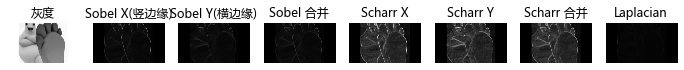

In [5]:
img = cv2.imread('res/nl_hd17.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sx = cv2.convertScaleAbs(cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3))
sy = cv2.convertScaleAbs(cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3))
sxy = cv2.addWeighted(sx, 0.5, sy, 0.5, 0)

kx = cv2.convertScaleAbs(cv2.Scharr(gray, cv2.CV_32F, 1, 0))
ky = cv2.convertScaleAbs(cv2.Scharr(gray, cv2.CV_32F, 0, 1))
kxy = cv2.addWeighted(kx, 0.5, ky, 0.5, 0)

lap = cv2.convertScaleAbs(cv2.Laplacian(gray, cv2.CV_32F))

show_img(gray, sx, sy, sxy, kx, ky, kxy, lap,
         titles=["灰度", "Sobel X(竖边缘)", "Sobel Y(横边缘)", "Sobel 合并",
                 "Scharr X", "Scharr Y", "Scharr 合并", "Laplacian"])


## 1.4 Canny：工程上最好用的边缘检测器

### 四个步骤

| 步骤 | 做什么 | 作用 |
| --- | --- | --- |
| 1. 高斯滤波 | 去噪 | 否则噪点会被当成边缘 |
| 2. 计算梯度 | Sobel，得到**幅值 + 方向** | 找候选边缘 |
| 3. **非极大值抑制 NMS** | 沿梯度方向只保留局部最大 | **把边缘细化到 1 像素宽** |
| 4. **双阈值 + 滞后连接** | 强边缘保留，弱边缘只有连着强边缘才保留 | 去掉噪点，同时不让边缘断掉 |

### 双阈值怎么理解

设 `t1 < t2`（经验比例 **1 : 2 ~ 1 : 3**）：

```text
梯度 >= t2        -> 强边缘，一定是边缘，保留
t1 < 梯度 < t2    -> 弱边缘，只有当它与某个强边缘"连通"时才保留
梯度 <= t1        -> 丢弃
```

这就是为什么 Canny 的边缘**又干净又连续**。

### 参数影响

| 现象 | 调整 |
| --- | --- |
| 边缘太多、全是噪点 | 提高 `t1/t2`，或先做滤波 |
| 边缘断裂、漏检 | 降低 `t1/t2` |
| 想要更细的边缘 | Canny 本身就是 1 像素宽 |

### ⚠️ 预处理会显著影响 Canny

- **高斯滤波**：去噪均匀，但边缘会被糊掉一点
- **双边滤波**：去噪同时**保边**，通常能得到更干净的边缘

> 结论：**默认先做双边滤波再 Canny**。


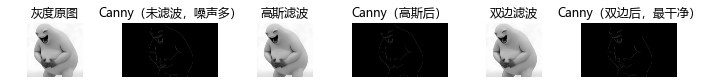

In [6]:
img = cv2.imread('res/nl_hd01.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

gauss = cv2.GaussianBlur(gray, (7, 7), 1.8)
bilat = cv2.cvtColor(cv2.bilateralFilter(img, 15, 80, 80), cv2.COLOR_BGR2GRAY)

show_img(
    gray,                cv2.Canny(gray, 60, 160),
    gauss,               cv2.Canny(gauss, 60, 160),
    bilat,               cv2.Canny(bilat, 60, 160),
    titles=["灰度原图", "Canny（未滤波，噪声多）",
            "高斯滤波", "Canny（高斯后）",
            "双边滤波", "Canny（双边后，最干净）"])


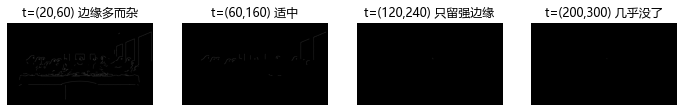

经验：t1 : t2 保持 1:2~1:3；先调 t2（决定'什么算强边缘'），再调 t1


In [7]:
# 双阈值的影响
img = cv2.imread('res/nl_classic1.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.bilateralFilter(gray, 15, 80, 80)

show_img(cv2.Canny(blur, 20, 60),
         cv2.Canny(blur, 60, 160),
         cv2.Canny(blur, 120, 240),
         cv2.Canny(blur, 200, 300),
         titles=["t=(20,60) 边缘多而杂", "t=(60,160) 适中", "t=(120,240) 只留强边缘", "t=(200,300) 几乎没了"])

print("经验：t1 : t2 保持 1:2~1:3；先调 t2（决定'什么算强边缘'），再调 t1")


## 1.5 第 1 章练习

1. 对 `nl_think.png`（白底）做 Canny，观察是否把物体**轮廓**完整勾出来了；调 `t1/t2` 找最合适的一组。
2. 用 `nl_galaxy.png`（暗图）做 Canny，说明为什么暗图更难检测边缘，以及可以先做什么预处理。
3. 比较 `cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)` 与 `ksize=5/7` 的差异。
4. 把 `cv2.Laplacian` 分别作用在"原图"和"高斯滤波后"，说明为什么后者更好。
5. **思考题**：Canny 的第 3 步"非极大值抑制"解决了什么问题？
   如果去掉这一步，边缘会变成什么样？
6. **思考题**：为什么 Canny 需要"滞后连接"？只用单阈值会有什么问题？


---

# 第 2 章 二值化与阈值

> 🎯 **学习目标**：搞清 `cv2.threshold` 的 5 种类型分别在干什么，会在合适的时候
> 换成 OTSU 或自适应阈值。
> 💡 **小贴士**：轮廓、形态学、霍夫的输入**都必须是二值图**。
> 这一章就是后面所有章节的"总闸门"——闸门没调好，后面全白搭。

## 2.1 为什么要二值化

`cv2.findContours`、`cv2.morphologyEx`、`cv2.HoughLines` 这些函数都要求
**单通道二值图**（每个像素只有 0 和 255 两种值）。

所以流程永远是：

```text
彩色图 --cvtColor--> 灰度图 --threshold--> 二值图 --findContours--> 轮廓
```

`cv2.threshold(src, thresh, maxval, type)` —— 四个参数：

| 参数 | 含义 |
| --- | --- |
| `src` | 输入，**必须是单通道**（灰度图） |
| `thresh` | 阈值 |
| `maxval` | 要被"点亮"的像素赋成多少，一般写 255 |
| `type` | **用哪种规则切**，见下表 |

> ⚠️ **易错点**：`cv2.threshold` 对类型是有要求的（实测）——
> 支持 `uint8` / `uint16` / `int16` / `float32` / `float64`，**唯独不支持 `int32`**；
> 而且只吃**单通道**图，彩色图要先 `cvtColor`。
> 此外 **OTSU 和三角法只支持 8 位单通道图**。
>
> `CV_8U` ↔ `np.uint8`、`CV_32F` ↔ `np.float32` 这一整套对照表，
> 以及"`ddepth` 为什么能让边缘显出来"，在**本讲义第 6 章 6.1 节**。

## 2.2 五种 `type`

| `type` | 规则 | 一句话 |
| --- | --- | --- |
| `THRESH_BINARY` | > 阈值 的 → `maxval`，其余 → 0 | 亮的变白，暗的变黑 |
| `THRESH_BINARY_INV` | **反过来** | 暗的变白（白底抠图最常用） |
| `THRESH_TRUNC` | > 阈值 的 → 截断成阈值本身，其余不变 | 高光被"削平" |
| `THRESH_TOZERO` | ≤ 阈值 的 → 0，其余不变 | 暗部压黑 |
| `THRESH_TOZERO_INV` | > 阈值 的 → 0，其余不变 | 亮部压黑 |

> 💡 **小贴士**：工程里 95% 的情况只用得上前两个：
> `THRESH_BINARY`（亮目标）和 `THRESH_BINARY_INV`（暗目标 / 白底抠图）。

**光看表格记不住？看曲线。** 横轴输入灰度、纵轴输出灰度、虚线是阈值 T，
"折线怎么弯"就是这个 type 的规则：

![五种阈值类型的输入-输出曲线](res/threshold.png)

**再看官方文档的原式**，`TRUNC` 是"往上削平"、两个 `TOZERO` 是"某一边压成 0"，
一眼就分清了：

![阈值类型公式表（OpenCV 官方文档）](res/threshold_eq.png)

> 💡 **小贴士**：公式表最后三行**不是 type，是旗标（flag）**。
> `THRESH_OTSU` / `THRESH_TRIANGLE` 是"**帮我自动挑阈值**"的算法，
> 要用**按位或**加到 type 上（3.4 节会细讲）：
> ```python
> cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)      # 大津法，适合双峰直方图
> cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_TRIANGLE)  # 三角法，适合单峰、目标占比小
> ```

**返回值是两个**，别漏了第一个：

```python
ret, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
#   ^^^ 实际用的阈值（用 OTSU / 自适应时会和传进去的不一样）
```

THRESH_BINARY        输出里的取值: [0, 255] ...
THRESH_BINARY_INV    输出里的取值: [0, 255] ...
THRESH_TRUNC         输出里的取值: [0, 1, 2, 3, 4] ...
THRESH_TOZERO        输出里的取值: [0, 128, 129, 130, 131] ...
THRESH_TOZERO_INV    输出里的取值: [0, 1, 2, 3, 4] ...


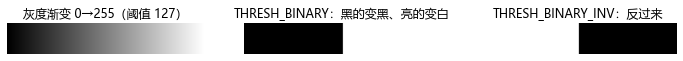

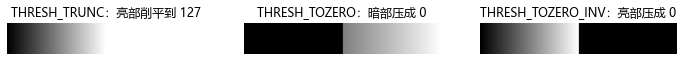


固定阈值 127 时，前景（白像素）占比 1.4%


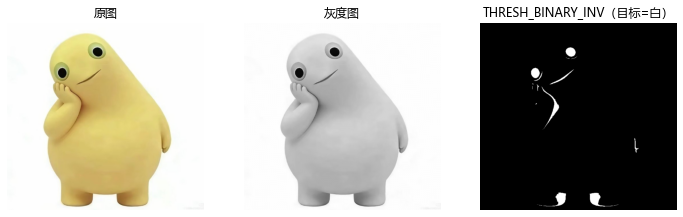

In [8]:
# 演示 1：五种阈值类型到底在干什么
# 用一条 0→255 的黑白渐变最直观：一眼就能看出每种规则"切"在哪、怎么切
ramp = np.tile(np.linspace(0, 255, 512, dtype=np.uint8), (80, 1))

types = [
    ('THRESH_BINARY',     cv2.THRESH_BINARY),
    ('THRESH_BINARY_INV', cv2.THRESH_BINARY_INV),
    ('THRESH_TRUNC',      cv2.THRESH_TRUNC),
    ('THRESH_TOZERO',     cv2.THRESH_TOZERO),
    ('THRESH_TOZERO_INV', cv2.THRESH_TOZERO_INV),
]

outs = {}
for name, t in types:
    _, out = cv2.threshold(ramp, 127, 255, t)
    outs[name] = out
    print(f"{name:20s} 输出里的取值: {sorted(set(np.unique(out).tolist()))[:5]} ...")

show_img(ramp, outs['THRESH_BINARY'], outs['THRESH_BINARY_INV'],
         titles=['灰度渐变 0→255（阈值 127）', 'THRESH_BINARY：黑的变黑、亮的变白',
                 'THRESH_BINARY_INV：反过来'])
show_img(outs['THRESH_TRUNC'], outs['THRESH_TOZERO'], outs['THRESH_TOZERO_INV'],
         titles=['THRESH_TRUNC：亮部削平到 127', 'THRESH_TOZERO：暗部压成 0',
                 'THRESH_TOZERO_INV：亮部压成 0'])

# 换到真实图片上看一眼（白底图 -> 反二值化 -> 目标变白）
img = cv2.imread('res/nl_think.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, bin_inv = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
print("\n固定阈值 127 时，前景（白像素）占比 %.1f%%" % (100 * np.count_nonzero(bin_inv) / bin_inv.size))
show_img(img, gray, bin_inv, titles=['原图', '灰度图', 'THRESH_BINARY_INV（目标=白）'])

写死的阈值             : 127   -> 前景占比 1.4%
OTSU 自己算出来的阈值  : 218  -> 前景占比 41.5%
bg_threshold 估的阈值  : 234

→ OTSU 更「聪明」，但前提是直方图真的有两座「山」（背景一座、目标一座）


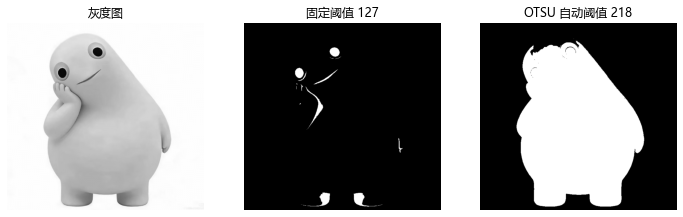

In [9]:
# 演示 2：固定阈值 vs OTSU 自动阈值
# OTSU（大津法）：自动找出"把灰度直方图分成两堆、两堆差别最大"的那个阈值
# 用法：thresh 参数写 0 占位，type 里再按位或上 cv2.THRESH_OTSU
img = cv2.imread('res/nl_think.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

_, bin_fixed = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
thr_otsu, bin_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)

print("写死的阈值             : 127   -> 前景占比 %.1f%%" % (100 * np.count_nonzero(bin_fixed) / bin_fixed.size))
print("OTSU 自己算出来的阈值  : %.0f  -> 前景占比 %.1f%%" % (thr_otsu, 100 * np.count_nonzero(bin_otsu) / bin_otsu.size))
print("bg_threshold 估的阈值  : %d" % bg_threshold(gray))
print("\n→ OTSU 更「聪明」，但前提是直方图真的有两座「山」（背景一座、目标一座）")

show_img(gray, bin_fixed, bin_otsu,
         titles=['灰度图', '固定阈值 127', 'OTSU 自动阈值 %.0f' % thr_otsu])

> ⚠️ **易错点**：`THRESH_OTSU` 是**按位或**加到 `type` 上的，不是单独一个参数：
> ```python
> cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)   # 对
> cv2.threshold(gray, 0, 255, cv2.THRESH_OTSU)                       # 错（没告诉它用哪种规则）
> ```
> 而且 OTSU 只支持 8 位单通道图，且图像不能是"全亮"或"全暗"。

固定阈值   前景占比 49.0%  <- 左边整块糊了
自适应阈值 前景占比 98.4%  <- 左边恢复


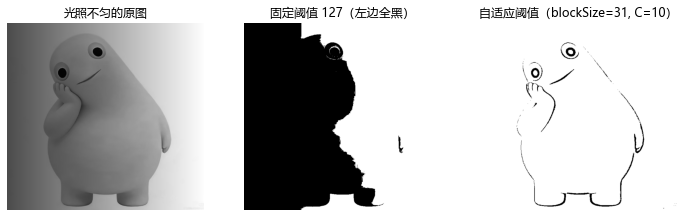


选阈值的顺序：
  1. 背景干净、光照稳定            -> 固定阈值（或 bg_threshold 估一个）
  2. 直方图明显双峰（背景/目标分明）-> OTSU，自动且稳
  3. 光照不匀、有渐变阴影          -> 自适应阈值



In [10]:
# 演示 3：自适应阈值 —— 光照不匀时固定阈值会直接失效
# 先造一张"光照从左到右逐渐变亮"的图：
gray0 = cv2.cvtColor(cv2.imread('res/nl_think.png'), cv2.COLOR_BGR2GRAY)
shade = np.linspace(0.30, 1.0, gray0.shape[1], dtype=np.float32).reshape(1, -1)
uneven = np.clip(gray0 * shade, 0, 255).astype(np.uint8)

# ① 固定阈值：左边整块背景都掉到 127 以下，全变黑，目标直接被吞掉
_, bin_fixed = cv2.threshold(uneven, 127, 255, cv2.THRESH_BINARY)

# ② 自适应阈值：对每个像素，只跟它"周围一圈"比，和整体亮度无关
bin_adapt = cv2.adaptiveThreshold(
    uneven, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,   # 邻域权重：高斯（也可以用 MEAN 算平均）
    cv2.THRESH_BINARY,                # 只能配 BINARY / BINARY_INV 两种
    31,                               # blockSize：邻域边长，必须是奇数
    10,                               # C：算出的阈值再减去这个常数
)

print("固定阈值   前景占比 %.1f%%  <- 左边整块糊了" % (100 * np.count_nonzero(bin_fixed) / bin_fixed.size))
print("自适应阈值 前景占比 %.1f%%  <- 左边恢复" % (100 * np.count_nonzero(bin_adapt) / bin_adapt.size))

show_img(uneven, bin_fixed, bin_adapt,
         titles=['光照不匀的原图', '固定阈值 127（左边全黑）', '自适应阈值（blockSize=31, C=10）'])

# 三个阈值方案的定位：什么时候用哪个
print("""
选阈值的顺序：
  1. 背景干净、光照稳定            -> 固定阈值（或 bg_threshold 估一个）
  2. 直方图明显双峰（背景/目标分明）-> OTSU，自动且稳
  3. 光照不匀、有渐变阴影          -> 自适应阈值
""")

### ✍️ 练习

1. 对 `res/nl_side.png` 的灰度图分别用 5 种 `type` 各做一次，打印白像素占比，
   解释为什么 `TRUNC` 和 `TOZERO` 的"白像素占比"没有意义。
2. 把 `THRESH_BINARY_INV` 换成 `THRESH_BINARY` 重新跑演示 1 的最后一格，看看二值图变成什么样，解释原因。
3. 对 `res/nl_santa.png` 分别用 `OTSU` 和 `bg_threshold()` 求阈值，比较两个数字，猜哪个更适合"白底抠图"。
4. 用自适应阈值处理 `res/nl_hd17.jpg` 的灰度图，试 `blockSize = 11 / 31 / 61` 和 `C = 5 / 10 / 20`，
   找出能稳定分出目标的一组参数。
5. 把 `blockSize` 改成 **偶数**（比如 30），看报什么错，并解释为什么必须是奇数。
6. **思考题**：`cv2.threshold` 只能处理单通道，那想在**彩色图**上按颜色切分该用什么？（回看必修的 `cv2.inRange`）

---

# 第 3 章 轮廓检测

## 3.1 `cv2.findContours`

```python
contours, hierarchy = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
```

### ⚠️ 前提：输入必须是**单通道二值图**

调用前必须先做 `threshold` / `inRange` / `Canny`。
如果传了彩色图，会直接报错。

### `mode`：检索哪些轮廓

| mode | 说明 |
| --- | --- |
| `RETR_EXTERNAL` | 只取**最外层**轮廓（最常用） |
| `RETR_LIST` | 所有轮廓，扁平列表 |
| `RETR_CCOMP` | 两层：外轮廓 + 内孔 |
| `RETR_TREE` | 完整层级树（带 `hierarchy` 关系） |

### `method`：怎么存轮廓点

| method | 说明 |
| --- | --- |
| `CHAIN_APPROX_NONE` | 存边界上**所有**点（点多、慢） |
| `CHAIN_APPROX_SIMPLE` | 只存**拐点**（直线段中间的冗余点被压缩，**推荐**） |

> 老版本 OpenCV 的 `findContours` 会**修改输入图**；保险起见传 `binary.copy()`。

## 3.2 轮廓的特征

| 函数 | 返回 | 用途 |
| --- | --- | --- |
| `cv2.contourArea(c)` | 面积 | 过滤小噪点 |
| `cv2.arcLength(c, True)` | 周长（闭合） | 形状规整度 |
| `cv2.isContourConvex(c)` | 是否凸 | 区分凸/凹 |
| `cv2.approxPolyDP(c, eps, True)` | 多边形逼近 | 判断是几边形 |
| `cv2.moments(c)` | 矩 | 求**质心** |

**质心**：

$$c_x=\frac{M_{10}}{M_{00}},\qquad c_y=\frac{M_{01}}{M_{00}}$$

### 用近似顶点数判断形状（经典套路）

```python
peri = cv2.arcLength(c, True)
approx = cv2.approxPolyDP(c, 0.02 * peri, True)
# len(approx) == 3 -> 三角形；== 4 -> 四边形；> 6 -> 圆/不规则
```

自动阈值 = 234，前景占比 = 43.0%
轮廓数量: 1


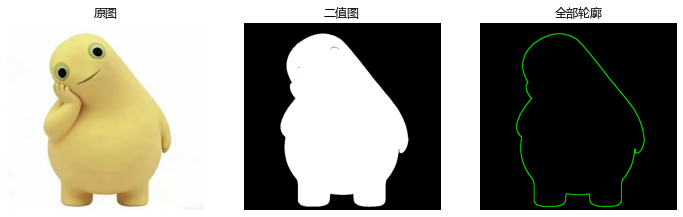

In [11]:
img = cv2.imread('res/nl_think.png')          # 白底 + 奶蛙，适合做轮廓
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 阈值交给第 0 章的 bg_threshold 自动估 —— 不要在固定背景上写死 200
thr = bg_threshold(gray)
_, binary = cv2.threshold(gray, thr, 255, cv2.THRESH_BINARY_INV)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
print("自动阈值 = %d，前景占比 = %.1f%%" % (thr, 100 * np.count_nonzero(binary) / binary.size))

contours, hierarchy = cv2.findContours(binary.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("轮廓数量:", len(contours))

canvas = np.zeros_like(img)
cv2.drawContours(canvas, contours, -1, (0, 255, 0), 2)

show_img(img, binary, canvas, titles=["原图", "二值图", "全部轮廓"])

# ⚠️ 为什么不能写死 200：
#    奶蛙浅黄色的身体灰度有 210 左右，比 200 还亮 ——
#    按「灰度 > 200 就算背景」来切，身体会被切开，只剩深色轮廓，
#    后面「取最大轮廓再框出来」就只能框到腿上的一小块。
#    bg_threshold 从图像四条边估背景亮度，再往下压 20 灰阶，换图换光照都不用重调。

In [12]:
# 检索模式对比：EXTERNAL vs LIST vs TREE
for mode, name in [(cv2.RETR_EXTERNAL, "EXTERNAL"), (cv2.RETR_LIST, "LIST"), (cv2.RETR_TREE, "TREE")]:
    cts, _ = cv2.findContours(binary.copy(), mode, cv2.CHAIN_APPROX_SIMPLE)
    print(f"{name:9s} 轮廓数 = {len(cts)}")

# 逼近方法对比：点的数量
for m, name in [(cv2.CHAIN_APPROX_NONE, "NONE"), (cv2.CHAIN_APPROX_SIMPLE, "SIMPLE")]:
    cts, _ = cv2.findContours(binary.copy(), cv2.RETR_EXTERNAL, m)
    if cts:
        print(f"{name:9s} 最大轮廓点数 = {len(max(cts, key=cv2.contourArea))}")


EXTERNAL  轮廓数 = 1


LIST      轮廓数 = 13
TREE      轮廓数 = 13
NONE      最大轮廓点数 = 1694
SIMPLE    最大轮廓点数 = 753


轮廓0: 面积= 193559.0 周长=  1949.2 顶点数=  8 凸=False 质心=(332,359)


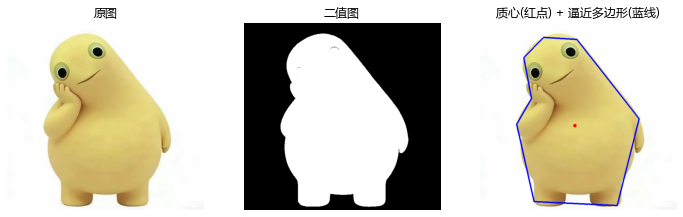

In [13]:
# 轮廓特征 + 质心 + 形状判断
canvas = img.copy()
rows = []
for i, c in enumerate(contours):
    area = cv2.contourArea(c)
    if area < 100:                       # 过滤噪点
        continue
    peri = cv2.arcLength(c, True)
    M = cv2.moments(c)
    cx, cy = int(M["m10"] / M["m00"]), int(M["m01"] / M["m00"])
    approx = cv2.approxPolyDP(c, 0.02 * peri, True)

    cv2.circle(canvas, (cx, cy), 6, (0, 0, 255), -1)          # 质心
    cv2.drawContours(canvas, [approx], -1, (255, 0, 0), 3)     # 逼近多边形
    rows.append((i, area, peri, len(approx), cv2.isContourConvex(c), (cx, cy)))

rows.sort(key=lambda t: -t[1])
for i, area, peri, nv, convex, (cx, cy) in rows[:5]:
    print(f"轮廓{i}: 面积={area:9.1f} 周长={peri:8.1f} 顶点数={nv:3d} 凸={convex} 质心=({cx},{cy})")

show_img(img, binary, canvas,
         titles=["原图", "二值图", "质心(红点) + 逼近多边形(蓝线)"])


eps = 0.001 * 周长  ->  顶点数 39
eps = 0.010 * 周长  ->  顶点数 13
eps = 0.050 * 周长  ->  顶点数 4


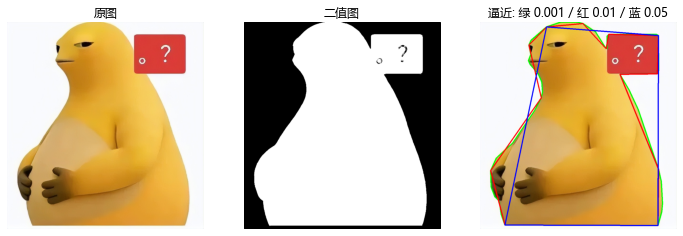

In [14]:
# approxPolyDP 的 eps 参数：越大，多边形越"粗"
img = cv2.imread('res/nl_question.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# 阈值同样交给 bg_threshold 自动估（问号气泡是浅色，写死 200 也会被切掉）
_, binary = cv2.threshold(gray, bg_threshold(gray), 255, cv2.THRESH_BINARY_INV)
cts, _ = cv2.findContours(binary.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
c = max(cts, key=cv2.contourArea)
peri = cv2.arcLength(c, True)

canvas = img.copy()
for ratio, color in [(0.001, (0, 255, 0)), (0.01, (0, 0, 255)), (0.05, (255, 0, 0))]:
    ap = cv2.approxPolyDP(c, ratio * peri, True)
    cv2.polylines(canvas, [ap], True, color, 3)
    print(f"eps = {ratio:.3f} * 周长  ->  顶点数 {len(ap)}")

show_img(img, binary, canvas,
         titles=["原图", "二值图", "逼近: 绿 0.001 / 红 0.01 / 蓝 0.05"])


## 3.3 第 3 章练习

1. 用 `nl_question.png` 找出**面积最大**的轮廓，画出它的逼近多边形，判断它是几边形。
2. 对比 `RETR_EXTERNAL` 与 `RETR_TREE` 在 `nl_angry.png` 上的轮廓数量差异，解释原因。
3. 用 `cv2.moments` 求所有轮廓的质心，把它们连成折线画在原图上。
4. 写一个 `classify_shape(c)`：用 `approxPolyDP` 的顶点数，返回"三角形/四边形/圆形/不规则"。
5. **思考题**：为什么 `CHAIN_APPROX_SIMPLE` 能"压缩点"而不改变轮廓形状？
6. **思考题**：如果先用 Canny 得到边缘，再用 `findContours`，得到的轮廓和用
   `threshold` 得到的有什么不同？（提示：边缘是"线"，阈值区域是"面"）

---

# 第 4 章 轮廓的外接形状

## 4.1 五种外接方式

| 函数 | 返回 | 特点 | 用途 |
| --- | --- | --- | --- |
| `cv2.boundingRect(c)` | `(x, y, w, h)` | **正**矩形（与坐标轴平行） | 快速定位、画框 |
| `cv2.minAreaRect(c)` | `((cx,cy),(w,h),angle)` | **可旋转**、面积最小 | 测真实尺寸、倾斜物体 |
| `cv2.boxPoints(rect)` | 4 个顶点 | 配合 `drawContours` 画旋转框 | |
| `cv2.minEnclosingCircle(c)` | `((cx,cy), r)` | 最小外接**圆** | 圆形物体测直径 |
| `cv2.convexHull(c)` | 凸包顶点 | 把凹进去的地方**填平** | 判断凸/凹、估外轮廓 |
| `cv2.approxPolyDP(c, eps, True)` | 近似多边形顶点 | 用 N 个顶点**近似**原轮廓 | 判断几边形、找四角 |

### 怎么选？

| 需求 | 选择 |
| --- | --- |
| 只要大致位置，画个框给人看 | `boundingRect`（最快） |
| 要测物体的**真实长宽 / 朝向** | `minAreaRect` |
| 物体接近圆形，要测**直径** | `minEnclosingCircle` |
| 要判断"这个形状是不是凹的" | `convexHull` + `isContourConvex` |
| 要取出"几个角点"（比如文档的四个角） | `approxPolyDP` |

> ⚠️ `minAreaRect` 返回的 `angle` 在不同 OpenCV 版本里定义不同（0~90 还是 -90~0）。
> **用之前先拿一个已知角度的矩形验证一下**，别直接写进公式里。

### 长宽比：很强的分类特征

```python
ratio = w / h
# 细长(ratio>2 或 <0.5) -> 可能是杆、线
# 接近 1 -> 可能是方形/圆
```

### 凸包和"最小外接多边形"的区别

- **凸包 `convexHull`**：把轮廓**绷上一根橡皮筋**，凹进去的地方全部被填平。
  点数是原轮廓的子集，但形状一定是凸的。
- **最小外接多边形 `approxPolyDP`**：用 Douglas-Peucker 算法把轮廓**简化**成
  更少的顶点，**保留原来的凹凸**。

> 💡 **小贴士**：`approxPolyDP` 的 `eps` 是"允许的最大误差"，单位是**像素**。
> `eps` 越大，顶点越少、多边形越"粗"。
> 经验值：`eps = 0.01 ~ 0.02 × arcLength(c, True)`。

① boundingRect       = (99,49,465,627)   长宽比 = 0.74
② minAreaRect        = 尺寸(444,641)  角度 -9.5°
③ minEnclosingCircle = 圆心(324,376)  半径 328
④ convexHull         = 62 个点   原轮廓凸吗? False   凸包当然凸? True
⑤ approxPolyDP       = 14 个顶点（eps = 周长的 1% = 19.9 像素）


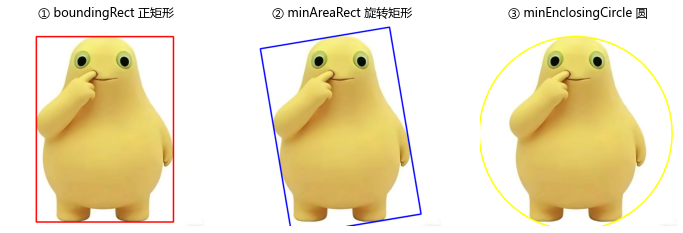

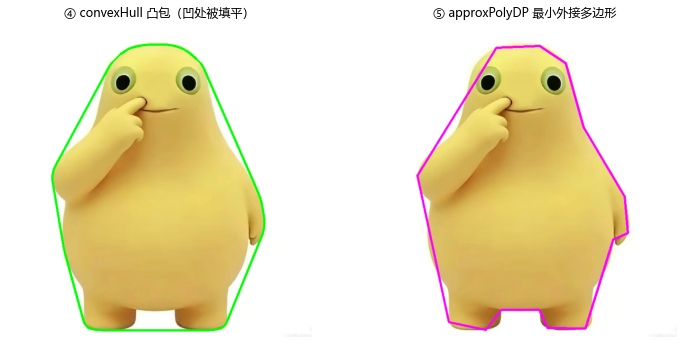

   eps = 0.001 × 周长  ->  55 个顶点
   eps = 0.010 × 周长  ->  14 个顶点
   eps = 0.020 × 周长  ->  6 个顶点
   eps = 0.050 × 周长  ->  5 个顶点


In [15]:
img = cv2.imread('res/nl_point.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, bg_threshold(gray), 255, cv2.THRESH_BINARY_INV)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
cts, _ = cv2.findContours(binary.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
c = max(cts, key=cv2.contourArea)          # 只处理最大的那个轮廓

rect_c, rot_c, cir_c, hull_c, poly_c = (img.copy() for _ in range(5))

# ① 正外接矩形
x, y, w, h = cv2.boundingRect(c)
cv2.rectangle(rect_c, (x, y), (x + w, y + h), (0, 0, 255), 3)
print(f"① boundingRect       = ({x},{y},{w},{h})   长宽比 = {w / h:.2f}")

# ② 最小外接旋转矩形
r_rect = cv2.minAreaRect(c)
box = cv2.boxPoints(r_rect).astype(np.int32)
cv2.drawContours(rot_c, [box], -1, (255, 0, 0), 3)
print(f"② minAreaRect        = 尺寸({r_rect[1][0]:.0f},{r_rect[1][1]:.0f})  角度 {r_rect[2]:.1f}°")

# ③ 最小外接圆
(cx, cy), r = cv2.minEnclosingCircle(c)
cv2.circle(cir_c, (int(cx), int(cy)), int(r), (0, 255, 255), 3)
print(f"③ minEnclosingCircle = 圆心({cx:.0f},{cy:.0f})  半径 {r:.0f}")

# ④ 凸包：把轮廓"绷紧"，凹的地方被填平
hull = cv2.convexHull(c)
cv2.drawContours(hull_c, [hull], -1, (0, 255, 0), 3)
print(f"④ convexHull         = {len(hull)} 个点   "
      f"原轮廓凸吗? {cv2.isContourConvex(c)}   凸包当然凸? {cv2.isContourConvex(hull)}")

# ⑤ 最小外接多边形：主要用来看"几个顶点"，也是自动找角点的标准做法
peri = cv2.arcLength(c, True)
poly = cv2.approxPolyDP(c, 0.01 * peri, True)
cv2.polylines(poly_c, [poly], True, (255, 0, 255), 3)
print(f"⑤ approxPolyDP       = {len(poly)} 个顶点（eps = 周长的 1% = {0.01 * peri:.1f} 像素）")

show_img(rect_c, rot_c, cir_c, titles=['① boundingRect 正矩形', '② minAreaRect 旋转矩形', '③ minEnclosingCircle 圆'])
show_img(hull_c, poly_c, titles=['④ convexHull 凸包（凹处被填平）', '⑤ approxPolyDP 最小外接多边形'])

# 换个 eps 看看顶点数怎么变（这就是第 3 章 approxPolyDP 的"粗/细"旋钮）
for ratio in (0.001, 0.01, 0.02, 0.05):
    print(f"   eps = {ratio:.3f} × 周长  ->  {len(cv2.approxPolyDP(c, ratio * peri, True))} 个顶点")

## 4.2 综合：自动定位并框出奶蛙

把前面所有内容串起来 —— 这就是"物体定位"的标准流水线：

```text
灰度 -> 阈值/反相 -> 形态学清理 -> findContours
     -> 取面积最大的轮廓 -> 过滤太小/太大 -> boundingRect 框出来
```

再加一步**长宽比过滤**，就能排除掉奇形怪状的干扰。

> ⚠️ **踩过的坑：阈值不能写死。**
> 奶蛙浅黄色的身体灰度大约 **210**，如果用「灰度 > 200 就算背景」去切，
> 身体会被切成碎片，只剩深色轮廓 —— 于是「最大轮廓」变成腿上的一小块，
> 框出来就是 `nl_angry.png` 那种明显偏小的框。
>
> 这就是第 0 章 `bg_threshold()` 存在的意义：**从图像四条边估出背景亮度，再往下压 20 灰阶**。
> 阈值跟着背景走，换一张图、换一次光照都不需要重调。
>
> 另外这里多了一步 `MORPH_CLOSE`（闭运算）：把被高光或阴影切开的身体**重新连成一整块**，
> 这样 `findContours` 拿到的才是完整的外轮廓，而不是一堆碎片。


think     -> {'area': 194974, 'bbox': (128, 37, 448, 618), 'aspect': 0.72}


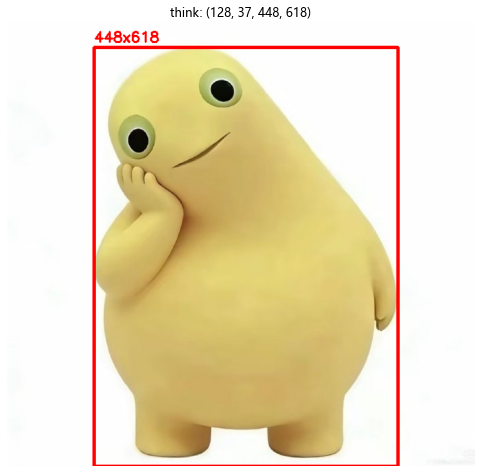

side      -> {'area': 52181, 'bbox': (18, 0, 255, 302), 'aspect': 0.84}


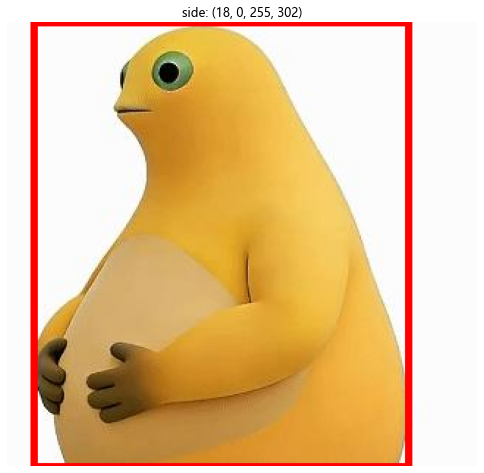

question  -> {'area': 455447, 'bbox': (43, 0, 721, 850), 'aspect': 0.85}


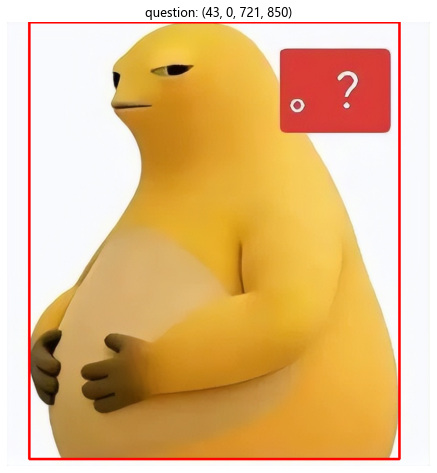

angry     -> {'area': 147038, 'bbox': (147, 77, 397, 513), 'aspect': 0.77}


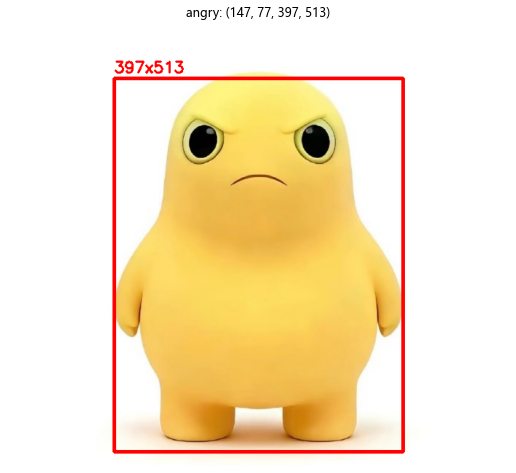

In [16]:
def locate_object(frame, min_area_ratio=0.005, aspect_range=(0.3, 3.0)):
    """自动定位画面中的主要物体，返回 (可视化图, 信息dict)。"""
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    # 阈值自动估（见第 0 章的 bg_threshold），不要在固定背景上写死 200
    _, binary = cv2.threshold(gray, bg_threshold(gray), 255, cv2.THRESH_BINARY_INV)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    # 闭运算：把被高光/阴影切开的身体重新连成一整块
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))

    cts, _ = cv2.findContours(binary.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    total = frame.shape[0] * frame.shape[1]

    vis = frame.copy()
    best = None
    for c in cts:
        area = cv2.contourArea(c)
        if area < total * min_area_ratio:
            continue
        x, y, w, h = cv2.boundingRect(c)
        ratio = w / max(h, 1)
        if not (aspect_range[0] <= ratio <= aspect_range[1]):
            continue                                  # 长宽比不合适 -> 丢弃
        if best is None or area > best[0]:
            best = (area, x, y, w, h)

    info = {}
    if best:
        area, x, y, w, h = best
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 3)
        cv2.putText(vis, f"{w}x{h}", (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        info = {"area": int(area), "bbox": (x, y, w, h), "aspect": round(w / h, 2)}
    else:
        cv2.putText(vis, "not found", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)
    return vis, info


for key in ["think", "side", "question", "angry"]:
    vis, info = locate_object(cv2.imread(f'res/nl_{key}.png'))
    print(f"{key:9s} -> {info}")
    show_img(vis, titles=[f"{key}: {info.get('bbox', '未检测到')}"])


## 4.3 第 4 章练习

1. 用 `nl_yellow.png` 找出最大轮廓，分别用**五种**方式画出外接形状，说明各自宽高的差异。
2. 给 `locate_object` 增加一个 `max_area_ratio` 参数，过滤掉"占了半张图"的误检。
3. 用 `minAreaRect` 测出 `nl_question.png` 中问号气泡的**倾斜角度**，并把它旋转回水平。
   （提示：`cv2.getRotationMatrix2D` + `cv2.warpAffine`）
4. 分别对 `nl_point.png` 和 `nl_angry.png` 求 `convexHull`，比较"凸包面积 / 轮廓面积"这个比值，
   说明它能不能当"这个形状有多凹"的指标。
5. 把演示里的 `eps` 从 0.01×周长 调到 0.05×周长，观察 `approxPolyDP` 的顶点数怎么变，
   并找出让 `nl_question.png` 的轮廓恰好变成 **4 个顶点**的那个 `eps`。
6. **思考题**：为什么工业检测里常用 `minAreaRect` 而不是 `boundingRect`？

## 4.4 综合练习：给梅花桩做预处理

前面学的"二值化 → 形态学清理 → 轮廓 → 外接形状"是一条完整的流水线。
现在拿 `res/MHZ.png`（梅花桩）来走一遍。

**梅花桩是红色的**，所以有一个更省事的方向：
不用灰度阈值，而是转到 HSV 之后**只取某个通道**——
比如 `S`（饱和度）通道，红色区域的饱和度会明显偏高，背景偏白则饱和度很低。

> 🎯 目标：写一个 `process_MHZ(img)`，**返回梅花桩的四个角点坐标**。
> 这是**必修第 9 章第 6 节**"自动透视矫正"的前置步骤。

**提示路线**：

```text
bilateralFilter / GaussianBlur   ->  去噪
转 HSV，取 S 通道（或灰度取红通道）->  让红色更突出
threshold / OTSU                 ->  二值化
morphologyEx(OPEN/CLOSE)         ->  清掉小白点、补上小洞
findContours + 取最大轮廓         ->  找到梅花桩
approxPolyDP(0.02 * 周长)         ->  取四个角点
```

**验收标准**：

- `cv2.isContourConvex` 结果为 `True`
- `approxPolyDP` 的顶点数正好是 **4**

MHZ.png 尺寸: (667, 630, 3)


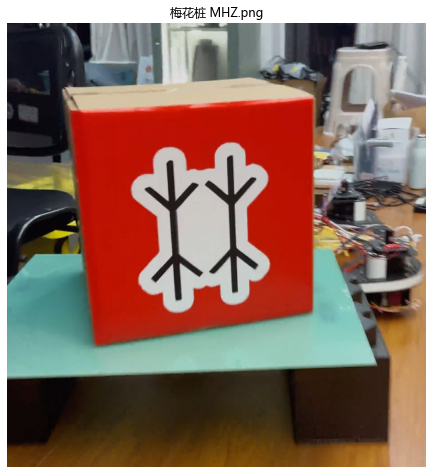

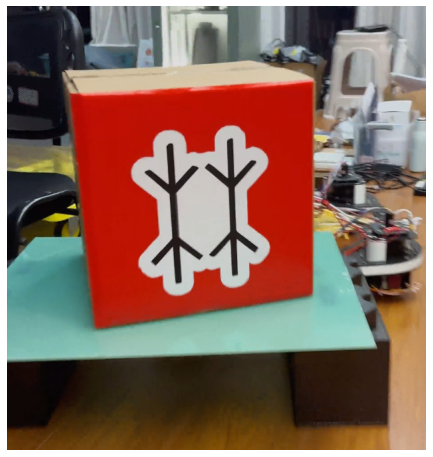

In [17]:
img_MHZ = cv2.imread('res/MHZ.png')
print("MHZ.png 尺寸:", img_MHZ.shape)
show_img(img_MHZ, titles=['梅花桩 MHZ.png'])


def process_MHZ(img: np.ndarray) -> np.ndarray:
    """找出梅花桩的四个角点。

    Args:
        img: BGR 图像
    Returns:
        形状 (4, 2) 的角点坐标（左上 -> 右上 -> 右下 -> 左下）
    """

    # ① 预处理：双边滤波去噪，同时保留边缘
    # img_blur = cv2.bilateralFilter(img, 9, 75, 75)

    # ② 转灰度 / 或者转 HSV 只取 S 通道（目标是红色，S 通道更明显）
    # img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # s_channel = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)[:, :, 1]

    # ③ 二值化（试试 OTSU）
    # _, img_bin = cv2.threshold(..., 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

    # ④ 形态学清理：开运算去小白点，闭运算补小洞
    # kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    # img_bin = cv2.morphologyEx(img_bin, cv2.MORPH_OPEN, kernel)
    # img_bin = cv2.morphologyEx(img_bin, cv2.MORPH_CLOSE, kernel)

    # ⑤ 找轮廓 + 取最大的那个
    # contours, _ = cv2.findContours(img_bin.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # contour = max(contours, key=cv2.contourArea)

    # ⑥ 用 approxPolyDP 取出四个角点
    # peri = cv2.arcLength(contour, True)
    # rect_points = cv2.approxPolyDP(contour, 0.02 * peri, True)

    # ⑦ 调试时把中间结果都画出来看看
    # canvas = img.copy()
    # cv2.drawContours(canvas, [rect_points], -1, (0, 0, 255), 3)
    # show_img(img_bin, canvas, titles=['二值图', '四个角点'])

    # ⑧ 检查验收标准
    # print("顶点数 =", len(rect_points), "  凸? =", cv2.isContourConvex(contour))

    show_img(img)
    # return rect_points.reshape(4, 2)


process_MHZ(img_MHZ)

---

# 第 5 章 霍夫变换

> 🎯 **学习目标**：会用 `cv2.HoughLines` / `HoughLinesP` / `HoughCircles`
> 检测直线、线段和圆，并知道关键参数怎么调。
> 💡 **小贴士**：霍夫变换是**车道线检测**、**文档边框检测**、**硬币计数**的常用武器。
> 它的输入必须是 **Canny 边缘图**（不是阈值二值图）。

## 5.1 霍夫变换在干什么

霍夫变换（Hough Transform）由 Paul Hough 在 1962 年提出，最早就是用来检测直线的。

它的核心思想一句话：

> **把"在图像里找一条直线"这个难题，变成"在参数空间里找一个峰值"这个简单问题。**

**换个坐标系表示直线**

初中平面几何告诉我们：从原点到任意一条给定直线作垂线，有且只有一条。
所以任意一条直线都可以用两个数唯一地表示：

| 参数 | 含义 |
| --- | --- |
| $r$ | 原点到这条直线的**垂线长度** |
| $\theta$ | 这条垂线与 $x$ 轴的**夹角** |

于是直线方程可以写成：

$$r = x\cos\theta + y\sin\theta$$

![极坐标表示直线](res/Hough_Polar.png)

**把点变成曲线，再找交点**

一个像素点 $(x_0, y_0)$ 固定后，上式就变成了一条**关于 $(\theta, r)$ 的正弦曲线** ——
也就是说，"所有可能经过这个点的直线"在 $\theta$-$r$ 空间里排成一条曲线。

那么，**过同一批像素点的那条直线**，在 $\theta$-$r$ 空间里就成了**这许多曲线的公共交点**：

![霍夫空间里的交点](res/Hough_thetar.png)

**具体四步**

1. 把参数空间**离散化**（比如 $\theta = 0°, 1°, 2°, \cdots$，$r = 0, 1, 2, \cdots$）；
2. 图像里每个**非零像素**，按映射关系在参数空间里对应的"格子"上投一票；
3. 统计每个格子得到的票数，**票数超过阈值的格子**就代表一条直线；
4. 把这些格子的 $(\theta, r)$ 作为图像中直线的参数。

**优缺点**

| 优点 | 缺点 |
| --- | --- |
| 抗干扰强，对**残缺的直线**、噪声、非直线结构不敏感 | 时间和空间复杂度都很高 |
| 能容忍边缘上的间隙 | 间隔取大了精度低，取小了算得慢 |

原图尺寸: (708, 897, 3)
边缘像素个数: 5418 （占比 0.85%）


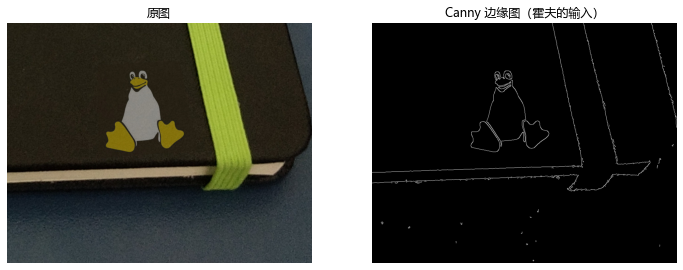

In [21]:
# 霍夫变换的输入：Canny 边缘图
img_h = cv2.imread('res/HoughLines.jpg')
img_h_gray = cv2.cvtColor(img_h, cv2.COLOR_BGR2GRAY)
img_edges = cv2.Canny(img_h_gray, 80, 180)

print("原图尺寸:", img_h.shape)
print("边缘像素个数:", np.count_nonzero(img_edges), "（占比 %.2f%%）" % (100 * np.count_nonzero(img_edges) / img_edges.size))
show_img(img_h, img_edges, titles=['原图', 'Canny 边缘图（霍夫的输入）'])

> ⚠️ **易错点**：霍夫变换要的是**边缘图**，不是阈值二值图。
> 阈值二值图给出的是"面"（一整块区域），边缘图给出的是"线"。
> 拿阈值二值图去做霍夫，检测出来的往往是区域的**边界**，结果会很怪。

## 5.2 直线检测：`cv2.HoughLines`

```python
lines = cv2.HoughLines(image, rho, theta, threshold[, srn, stn, min_theta, max_theta])
```

| 参数 | 作用 |
| --- | --- |
| `image` | 单通道二值图，**通常是 Canny 的输出** |
| `rho` | 距离 $r$ 的分辨率（像素）。`1` 表示以 1 像素为步长离散化 |
| `theta` | 角度 $\theta$ 的分辨率（弧度）。`np.pi/180` 表示以 1° 为步长 |
| `threshold` | **累加器阈值**：票数 ≥ 它才被判为直线。越大越严格、结果越少越可靠 |
| `srn` / `stn` | 多尺度霍夫（MSHT）的两个除数，都用 `0` 就是标准霍夫（SHT） |
| `min_theta` / `max_theta` | 只在这个角度范围内找，默认 `0 ~ π` |

**返回值**：形状 `(N, 1, 2)` 的 `ndarray`，每个元素是 `(rho, theta)`；
**一条都没检测到时返回 `None`**（不是空列表！）。

> ⚠️ **易错点**：`rho / theta` 是**极坐标**，不是端点坐标。
> 拿到 `(rho, theta)` 之后要自己换算成两个端点才能画线 —— 不能直接 `cv2.line`。
> 想直接拿到端点，用 7.3 的 `cv2.HoughLinesP`。

阈值 150 -> 检测到 4 条直线
阈值 100 -> 检测到 9 条直线

lines_hi 形状: (4, 1, 2)
每行是 (rho, theta)，前 3 条:
 [[ 442.           1.5358897]
 [ 471.           1.5358897]
 [-518.           2.9321532]]


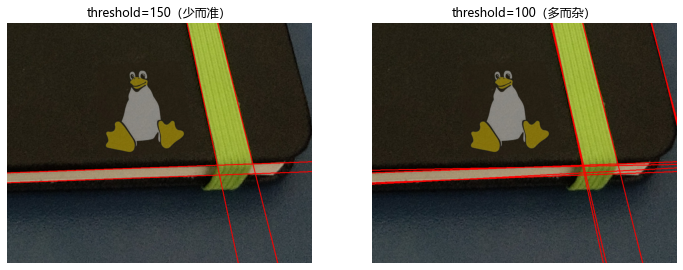

In [22]:
lines_hi = cv2.HoughLines(img_edges, 1, np.pi / 180, 150)   # 阈值高：少而准
lines_lo = cv2.HoughLines(img_edges, 1, np.pi / 180, 100)   # 阈值低：多而杂

print("阈值 150 -> 检测到 %d 条直线" % len(lines_hi))
print("阈值 100 -> 检测到 %d 条直线" % len(lines_lo))
print("\nlines_hi 形状:", lines_hi.shape)
print("每行是 (rho, theta)，前 3 条:\n", lines_hi[:3, 0])


def draw_hough_lines(image, lines, color=(0, 0, 255), thickness=2):
    """把 (rho, theta) 换算成两个端点，画出穿过整张图的长直线。"""
    out = image.copy()
    h, w = out.shape[:2]
    length = max(h, w)                                  # 延长到足够穿过整张图
    for line in lines:
        rho, theta = line[0]
        cos_t, sin_t = np.cos(theta), np.sin(theta)
        x0, y0 = rho * cos_t, rho * sin_t               # 直线上离原点最近的那个点
        p1 = (round(x0 - length * sin_t), round(y0 + length * cos_t))
        p2 = (round(x0 + length * sin_t), round(y0 - length * cos_t))
        cv2.line(out, p1, p2, color, thickness)
    return out


show_img(draw_hough_lines(img_h, lines_hi), draw_hough_lines(img_h, lines_lo),
         titles=['threshold=150（少而准）', 'threshold=100（多而杂）'])

## 5.3 线段检测：`cv2.HoughLinesP`

`cv2.HoughLines` 给的是"无限长的直线"，`cv2.HoughLinesP` 用的是**渐进概率霍夫变换（PPHT）**，
直接给出**线段的两个端点**，更适合实际使用。

```python
lines = cv2.HoughLinesP(image, rho, theta, threshold,
                        minLineLength=..., maxLineGap=...)
```

其中两个特殊参数：

| 参数 | 作用 |
| --- | --- |
| `minLineLength` | 最短线段长度，短于它的线段直接被剔除 |
| `maxLineGap` | 同一直线上相邻两段之间允许的最大间隙；间隙小于它就会被**接成一条** |

**返回值**：形状 `(N, 1, 4)` 的 `ndarray`，每个元素是 `(x1, y1, x2, y2)`；
检测不到时同样返回 `None`。

> 💡 **小贴士**：调参口诀 ——
> 线段太碎就把 `maxLineGap` 调**大**，噪声太多就把 `minLineLength` 调**大**。

maxLineGap=10 -> 7 条线段
maxLineGap=30 -> 6 条线段

每行是 (x1, y1, x2, y2)，前 3 条:
 [[435 427 549 424]
 [469 455 567 451]
 [  0 442 324 430]]


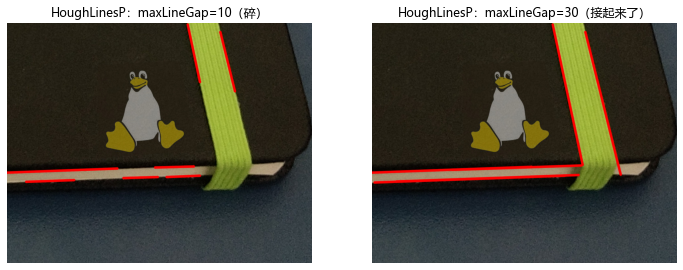

In [23]:
lines_p1 = cv2.HoughLinesP(img_edges, 1, np.pi / 180, 150, minLineLength=30, maxLineGap=10)
lines_p2 = cv2.HoughLinesP(img_edges, 1, np.pi / 180, 150, minLineLength=30, maxLineGap=30)

print("maxLineGap=10 -> %d 条线段" % len(lines_p1))
print("maxLineGap=30 -> %d 条线段" % len(lines_p2))
print("\n每行是 (x1, y1, x2, y2)，前 3 条:\n", lines_p1[:3, 0])


def draw_hough_segments(image, lines, color=(0, 0, 255), thickness=6):
    """HoughLinesP 直接给端点，画起来最简单。"""
    out = image.copy()
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(out, (x1, y1), (x2, y2), color, thickness, cv2.LINE_AA)
    return out


show_img(draw_hough_segments(img_h, lines_p1), draw_hough_segments(img_h, lines_p2),
         titles=['HoughLinesP：maxLineGap=10（碎）', 'HoughLinesP：maxLineGap=30（接起来了）'])

## 5.4 圆形检测：`cv2.HoughCircles`

圆的霍夫变换思路和直线一样，只是参数多了一个 —— 圆有两个方程：

$$
\begin{cases}
x = a + R\cos\theta \\
y = b + R\sin\theta
\end{cases}
$$

所以参数空间变成了 $(a, b, R)$ 三维：圆心 $a,b$ 加半径 $R$。

![圆的霍夫变换](res/Hough_circle.png)

```python
circles = cv2.HoughCircles(image, method, dp, minDist, param1, param2, minRadius, maxRadius)
```

| 参数 | 作用 |
| --- | --- |
| `image` | **单通道灰度图**（注意：不要二值化！函数内部会自己跑一遍 Canny） |
| `method` | 检测方法，常用的就 `cv2.HOUGH_GRADIENT` |
| `dp` | 累加器分辨率与图像分辨率的反比。`1` = 同分辨率，`2` = 分辨率减半（更快） |
| `minDist` | 检测到的**圆心之间**的最小距离。太小会检出很多相邻的重复圆，太大会漏 |
| `param1` | 传给内部 Canny 的**高阈值**（低阈值自动取它的一半），例如 200 |
| `param2` | **累加器阈值**。越小检出越多（也越多假圆） |
| `minRadius` / `maxRadius` | 只在这个半径范围内找 |

**返回值**：形状 `(1, N, 3)` 的 `ndarray`，每个圆是 `(x 圆心, y 圆心, radius)`；
检测不到时返回 `None`。

> ⚠️ **易错点**：`cv2.HoughCircles` 的 `image` 参数**不要传二值图**。
> 它内部依赖梯度信息，二值图已经被"压成两档"，梯度信息基本没了，检测效果会很差。
> 正确做法是灰度图（可以先轻微高斯滤波去噪）。

> ⚠️ **易错点**：没检测到圆时返回的是 `None`，直接 `circles[0]` 会崩。
> **先判 `if circles is None`**，这是霍夫三个函数共同的坑。

原图尺寸: (348, 500, 3)


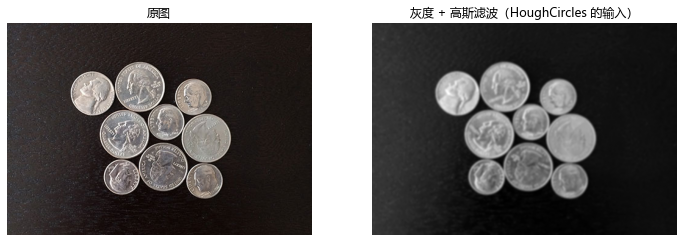

In [24]:
# 硬币图：先灰度，再轻微高斯滤波（去噪，但别把边缘抹掉）
img_c = cv2.imread('res/coins.jpg')
img_c_gray = cv2.cvtColor(img_c, cv2.COLOR_BGR2GRAY)
img_c_gray = cv2.GaussianBlur(img_c_gray, (7, 7), 1.5)

print("原图尺寸:", img_c.shape)
show_img(img_c, img_c_gray, titles=['原图', '灰度 + 高斯滤波（HoughCircles 的输入）'])

In [25]:
# param2（累加器阈值）越小，检出的圆越多、假圆也越多
results = {}
for param2 in (100, 60, 40):
    c = cv2.HoughCircles(img_c_gray, cv2.HOUGH_GRADIENT,
                         dp=2, minDist=10, param1=200, param2=param2,
                         minRadius=10, maxRadius=50)
    results[param2] = c
    print(f"param2={param2:3d} -> {'没检测到' if c is None else str(c.shape[1]) + ' 个圆'}")

best = results[100]
if best is not None:
    print("\n返回值形状:", best.shape, "（1, N, 3）")
    print("前 3 个圆 (x, y, r):\n", best[0][:3])

param2=100 -> 9 个圆
param2= 60 -> 12 个圆
param2= 40 -> 38 个圆

返回值形状: (1, 9, 3) （1, N, 3）
前 3 个圆 (x, y, r):
 [[191. 183.  40.]
 [327. 189.  40.]
 [217. 105.  40.]]


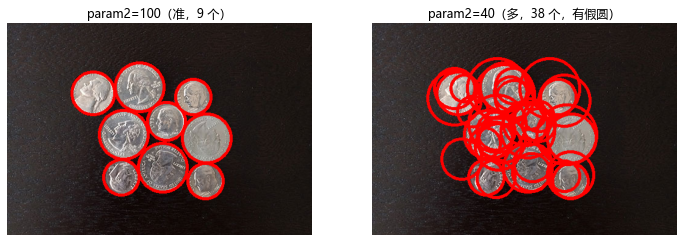

In [26]:
canvas_c = img_c.copy()
if best is not None:
    for x, y, r in best[0]:                      # x, y, r 都是浮点数
        cv2.circle(canvas_c, (round(x), round(y)), round(r), (0, 0, 255), 3)

loose = img_c.copy()
if results[40] is not None:
    for x, y, r in results[40][0]:                 # 注意：其实是 (1, N, 3)，要先取 [0]
        cv2.circle(loose, (round(x), round(y)), round(r), (0, 0, 255), 3)

show_img(canvas_c, loose, titles=['param2=100（准，9 个）', 'param2=40（多，38 个，有假圆）'])

> 💡 **小贴士**：圆检测调参的经验顺序 ——
> 先卡死 `minRadius / maxRadius`（把搜索范围缩小），再调 `param2`（控制松紧），
> 最后微调 `minDist`（控制重复圆的间隔）。

### ✍️ 练习

1. 把 `cv2.HoughLines` 的 `threshold` 从 150 一路降到 50，画出结果，说明"检测到的直线变多"和"结果变脏"是怎么同时发生的。
2. 把 `img_edges` 换成 `cv2.threshold` 得到的二值图，再跑一次霍夫直线，解释结果为什么不对。
3. 用 `cv2.HoughLinesP` 检测 `res/nl_hd17.jpg` 里的水平线（提示：结果里筛 `abs(y2 - y1) < 5` 的线段）。
4. 对 `res/coins.jpg` 用 `HOUGH_GRADIENT_ALT` 替换 `HOUGH_GRADIENT`（`dp` 改成 1.5），
   比较两者检出的圆的数量和准确度。
5. 把 `cv2.HoughCircles` 的输入换成 `cv2.threshold` 之后的二值图，跑一下并解释为什么效果变差。
6. **思考题**：霍夫变换能不能检测**任意形状**？如果能，需要付出什么代价？
   （提示：思考参数空间的维数）

---

# 第 6 章 图像的类型与浮点像素

> 🎯 **学习目标**：搞清楚 `dtype` 那七个名字怎么选、`ddepth` 为什么能"救回"边缘，
> 以及"像素带小数"时怎么安全地转回 `uint8`。
> 💡 **小贴士**：这一章是**必修第 3 章第 9 节（数值刻度）的续集**。
> 必修只讲了"有两把尺子、用哪把由 `dtype` 决定"；这里把 `dtype` 讲全、把小数讲透。
> 属于**深水区** —— 写算法、调 `ddepth`、做多帧平均时才会撞上。
> 第一次读可以略过，等遇到"边缘图全黑""图上有莫名其妙的黑点白点"再回来翻。



## 6.1 图像的类型：`8U` / `16U` / `32F` / `64F`

必修第 3 章第 9 节说"刻度由 `dtype` 决定"，这一节把 `dtype` 讲全。

**OpenCV 的名字 ↔ NumPy 的 `dtype`**

| OpenCV 名字 | 值 | NumPy `dtype` | 占几字节 | 取值范围 | 谁在用 |
| --- | --- | --- | --- | --- | --- |
| **`CV_8U`** | 0 | **`np.uint8`** | 1 | 0 ~ 255 | **默认**：读图 / 显示 / 存图 / 阈值 / 形态学 |
| `CV_8S` | 1 | `np.int8` | 1 | -128 ~ 127 | 基本不用 |
| `CV_16U` | 2 | `np.uint16` | 2 | 0 ~ 65535 | 深度图（Kinect、激光雷达） |
| `CV_16S` | 3 | `np.int16` | 2 | -32768 ~ 32767 | 卷积 / Sobel 的**中间结果** |
| `CV_32S` | 4 | `np.int32` | 4 | ±21 亿 | 连通域标记 |
| **`CV_32F`** | 5 | **`np.float32`** | 4 | ±3.4e38 | 浮点计算（**0~1 刻度**） |
| **`CV_64F`** | 6 | **`np.float64`** | 8 | ±1.8e308 | 高精度计算（`Sobel` / `Laplacian` 常用） |

> 💡 **小贴士**：`CV_8U` 那个数字不是随便定的 ——
> **`type = depth + (通道数 - 1) × 8`**。
> 所以 `CV_8UC3 = 0 + 2×8 = 16`，`CV_8UC4 = 0 + 3×8 = 24`；
> 单通道时 `CV_8U == CV_8UC1 == 0`。看懂这条，再看到 `CV_64FC3` 就不会懵了。

**Python 里怎么看类型？看 `img.dtype`**

```python
print(img.dtype, img.ndim, img.shape)      # 例如： uint8 3 (498, 500, 3)
```

> ⚠️ **易错点**：C++ 里用 `img.type()` / `img.depth()` 判断类型，
> **Python 里没有这两个方法**（`hasattr(img, 'depth')` 是 `False`）。
> 在 Notebook 里直接看 `img.dtype` + `img.shape` 就够了。

**⚠️ 不是所有函数都吃所有类型** —— 这是最容易踩的地方（下表都是实测结果）：

| 函数 | 支持的类型 |
| --- | --- |
| `cv2.cvtColor` | **只认** `uint8` / `uint16` / `float32` —— `float64`、`int32`、`int16` **全部报错** |
| `cv2.threshold` | `uint8` / `uint16` / `int16` / `float32` / `float64`（**唯独不支持 `int32`**） |
| `cv2.Canny` | `uint8`（16 位也行） |
| `cv2.imshow` / `cv2.imwrite` | 基本按 8 位处理 |
| `cv2.Sobel` / `Laplacian` / `filter2D` | 由 **`ddepth`** 参数说了算，见下 |

> ⚠️ **易错点**：`img.astype(float)` 得到的是 **`float64`**（Python 的 `float` 就是双精度），
> 而 `cvtColor` 不认 `float64` → 直接报 `(-2:Unspecified error) ... CvtHelper`。
> **必须写 `img.astype(np.float32)`。** 这是新手最常撞的一堵墙。

**`ddepth`：让中间结果保住负数**

`Sobel` / `Laplacian` / `filter2D` 都有个 `ddepth`（destination depth）参数，
意思是"**输出用什么类型**"。拿一张图做锐化卷积实测：

| `ddepth` | 输出 `dtype` | 数值范围 |
| --- | --- | --- |
| `-1`（或 `0`，= 跟输入一样） | `uint8` | **0 ~ 255** ← 负数全被截成 0 |
| `cv2.CV_16S` | `int16` | **-468 ~ 862** |
| `cv2.CV_32F` | `float32` | -468.0 ~ 862.0 |
| `cv2.CV_64F` | `float64` | -468.0 ~ 862.0 |

看清楚：**同一个卷积**，`ddepth=-1` 时最小值是 `0`，`ddepth=CV_16S` 时最小值是 `-468`。
那部分"负数"就是边缘信息，被 `uint8` 一刀切掉了 —— 这就是"边缘检测结果全黑"的根因。

要显示回来，再补一步：

```python
out = cv2.filter2D(gray, cv2.CV_32F, kernel)   # 第一步：用浮点保留负值
out = cv2.convertScaleAbs(out)                 # 第二步：取绝对值 + 转回 uint8
```

**`uint8` 会溢出（回绕）**

| 运算 | 结果 |
| --- | --- |
| `250 + 20`（NumPy 的 `+`） | **14** ← 回绕（255 + 1 又回到 0） |
| `250 + 20`（`cv2.add(a, 20)`） | **255** ← 饱和（封顶） |

> ⚠️ **易错点**：`img + 80` 在 `uint8` 上会**回绕**，亮的地方直接变成黑斑；
> `cv2.add(img, 80)` 才是有意义的"提亮"（超过 255 就停在 255，不会掉回来）。
> 想彻底避免，就先 `astype(np.float32)` 再算。

**存图：float 会被降级**

| 存什么 | 结果 |
| --- | --- |
| `uint8` | 正常 |
| `float32`，值在 **0 ~ 255** | 自动降级成 `uint8`（打一行警告），结果正确 |
| `float64` | 同上，也会降级 |
| `float32`，值在 **0 ~ 1** | ⚠️ 降级后 `0~1` 被当成 `0~1` 的 `uint8` → **存出来几乎全黑** |

> 💡 **小贴士**：要存 0~1 的 float 图，**先转回来再存**：
> `cv2.imwrite(path, (f * 255).astype(np.uint8))`。

> ❓ **自测**：为什么 `cv2.Sobel(gray, -1, 1, 0)` 的结果"什么都看不见"？
> （答：`-1` 表示输出和输入一样是 `uint8`，而 Sobel 会算出负数，负数被截断成 0。）

默认读进来的类型: uint8  每个像素占 1 字节
（C++ 里的 img.depth() 在 Python 里没有，看 dtype 就行）

OpenCV 名字 -> NumPy dtype:
  CV_8U    = 0       1 字节   0 ~ 255
  CV_8S    = 1       1 字节   -128 ~ 127
  CV_16U   = 2       2 字节   0 ~ 65535
  CV_16S   = 3       2 字节   -32768 ~ 32767
  CV_32S   = 4       4 字节   -2147483648 ~ 2147483647
  CV_32F   = 5       4 字节   -3.4028235e+38 ~ 3.4028235e+38
  CV_64F   = 6       8 字节   -1.7976931348623157e+308 ~ 1.7976931348623157e+308

type 的算法: type = depth + (通道数-1)*8
  CV_8U   = 0   CV_8UC1 = 0   CV_8UC3 = 16   CV_8UC4 = 24

同一个锐化卷积，不同 ddepth:
  ddepth=-1 -> dtype uint8    范围 0 ~ 255
  ddepth=3  -> dtype int16    范围 -467 ~ 866
  ddepth=5  -> dtype float32  范围 -467.0 ~ 866.0


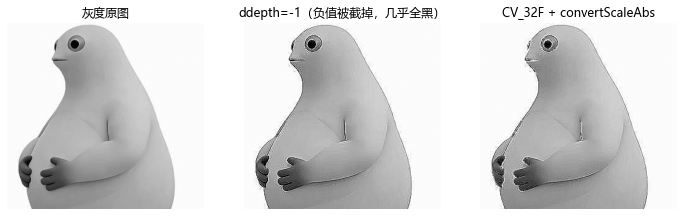

→ ddepth=-1 时最小值是 0，CV_16S 时是 -467，那部分负数就是边缘信息

cvtColor 对各类型的支持:
  uint8    OK   -> 输出 uint8
  uint16   OK   -> 输出 uint16
  float32  OK   -> 输出 float32
  float64  报错：error: (-2:Unspecified error) in function '__c
  int32    报错：error: (-2:Unspecified error) in function '__c
→ img.astype(float) 得到的是 float64，所以 cvtColor 会报错，要写 astype(np.float32)

250 + 20  NumPy  : [14]  <- 回绕成 14
250 + 20  cv2.add: [255]  <- 饱和到 255
250 - 20  NumPy  : [230]  <- 减法是安全的（没越过 0）



imwrite 两种 float32：
  值域 0~1   存回来均值 1.0（几乎全黑）
  值域 0~255 存回来均值 204.9（正常）
→ float 图要存，先 (f * 255).astype(np.uint8) 再 imwrite


In [2]:
# 演示 1：dtype 与 ddepth —— 7 种类型到底怎么选
img = cv2.imread('res/nl_side.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("默认读进来的类型:", gray.dtype, " 每个像素占", gray.dtype.itemsize, "字节")
print("（C++ 里的 img.depth() 在 Python 里没有，看 dtype 就行）")

# ① 七种类型对照
print("\nOpenCV 名字 -> NumPy dtype:")
for name, np_t in [('CV_8U', np.uint8), ('CV_8S', np.int8), ('CV_16U', np.uint16),
                   ('CV_16S', np.int16), ('CV_32S', np.int32),
                   ('CV_32F', np.float32), ('CV_64F', np.float64)]:
    info = np.iinfo(np_t) if np.issubdtype(np_t, np.integer) else np.finfo(np_t)
    print("  %-8s = %-6s  %d 字节   %s ~ %s"
          % (name, getattr(cv2, name), np.dtype(np_t).itemsize, info.min, info.max))

print("\ntype 的算法: type = depth + (通道数-1)*8")
print("  CV_8U   =", cv2.CV_8U, "  CV_8UC1 =", cv2.CV_8UC1,
      "  CV_8UC3 =", cv2.CV_8UC3, "  CV_8UC4 =", cv2.CV_8UC4)

# ② ddepth：同一个卷积，换个类型就天差地别
kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
print("\n同一个锐化卷积，不同 ddepth:")
outs = {}
for dd, name in [(-1, 'input（=uint8）'), (cv2.CV_16S, 'CV_16S'), (cv2.CV_32F, 'CV_32F')]:
    out = cv2.filter2D(gray, dd, kernel)
    outs[dd] = out
    print("  ddepth=%-2s -> dtype %-8s 范围 %s ~ %s" % (dd, out.dtype, out.min(), out.max()))

show_img(gray, outs[-1],
         cv2.convertScaleAbs(cv2.filter2D(gray, cv2.CV_32F, kernel)),
         titles=['灰度原图', 'ddepth=-1（负值被截掉，几乎全黑）', 'CV_32F + convertScaleAbs'])
print("→ ddepth=-1 时最小值是 0，CV_16S 时是 %d，那部分负数就是边缘信息" % outs[cv2.CV_16S].min())

# ③ cvtColor 只认 uint8 / uint16 / float32
print("\ncvtColor 对各类型的支持:")
base3 = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
for name, arr in [('uint8', base3), ('uint16', base3.astype(np.uint16)),
                  ('float32', base3.astype(np.float32)), ('float64', base3.astype(float)),
                  ('int32', base3.astype(np.int32))]:
    try:
        out = cv2.cvtColor(arr, cv2.COLOR_BGR2GRAY)
        print("  %-8s OK   -> 输出 %s" % (name, out.dtype))
    except cv2.error as e:
        msg = str(e)
        print("  %-8s 报错：%s" % (name, msg[msg.find('error:'):][:46].replace('\n', ' ')))
print("→ img.astype(float) 得到的是 float64，所以 cvtColor 会报错，要写 astype(np.float32)")

# ④ uint8 会回绕，cv2.add 会饱和
a = np.array([[250]], np.uint8)
print("\n250 + 20  NumPy  :", (a + 20).ravel(), " <- 回绕成 14")
print("250 + 20  cv2.add:", cv2.add(a, 20).ravel(), " <- 饱和到 255")
print("250 - 20  NumPy  :", (a - 20).ravel(), " <- 减法是安全的（没越过 0）")

# ⑤ 存图：0~1 的 float 直接存会变黑
f01 = gray.astype(np.float32) / 255.0
cv2.imwrite('out/dtype_float01.png', f01)
cv2.imwrite('out/dtype_float255.png', gray.astype(np.float32))
print("\nimwrite 两种 float32：")
print("  值域 0~1   存回来均值 %.1f（几乎全黑）" % cv2.imread('out/dtype_float01.png').mean())
print("  值域 0~255 存回来均值 %.1f（正常）" % cv2.imread('out/dtype_float255.png').mean())
print("→ float 图要存，先 (f * 255).astype(np.uint8) 再 imwrite")


## 6.2 像素带小数怎么办？—— 取整 / 裁剪 / 归一化 / 保存

`float32` / `float64` 里的像素值是**可以是小数**的（`127.35`、`-18.6`……）。
这一节讲清楚：小数从哪来、怎么显示、怎么变回 `uint8`、怎么存。

### 6.2.1 小数是从哪来的

| 来源 | 例子 |
| --- | --- |
| 浮点滤波 | 输入 `float32`，`GaussianBlur` / `bilateralFilter` 输出还是 `float32`，**实测 58% 的像素带小数** |
| 加权运算 | `cv2.addWeighted(a, 0.3, b, 0.7, 0)` |
| 归一化 | `img / 255.0` |
| 多帧平均 | 视频逐帧累加求平均降噪 |
| 坐标变换 | 旋转 / 透视重采样时的插值 |
| 亚像素测量 | 质心、`minAreaRect` 的中心本来就是小数 |

> ⚠️ **关键规矩：OpenCV 的类型跟着输入走。**
> 输入 `float32`，`cvtColor` / `threshold` / `erode` / `resize` 的输出**全都是 `float32`**，
> **小数会一路留着**。想变回 `uint8`，必须**自己动手转**。

### 6.2.2 ⚠️ 头号大坑：`astype(np.uint8)` 不是四舍五入，也不管负数

`astype` 干的是 **C 语言的强制类型转换**：正数**截断**（向下取整），
负数 / 超过 255 的值按二进制**回绕**。实测：

| 输入 | `.astype(np.uint8)` | 说明 |
| --- | --- | --- |
| `0.6` | `0` | **截断**，不是四舍五入成 1 |
| `1.6` | `1` | 同上 |
| `127.5` | `127` | ⚠️ 四舍五入本该是 128 |
| `254.6` | `254` | 同上 |
| **`-1.5`** | **`255`** | 💥 **负数是"回绕"，直接变成纯白点！** |
| **`-2.7`** | **`254`** | 💥 同上 |
| **`300.6`** | **`44`** | 💥 超过 255 也会回绕成 44 |

所以：**只要结果有可能为负、或有可能超过 255，就绝对不能直接 `astype`**。
（`Sobel` / `Laplacian` / 锐化卷积的结果全都可能为负 —— 这正是"边缘图出现莫名其妙白点"的常见原因。）

### 6.2.3 正确姿势：`clip` → `round` → `astype`

```python
u8 = np.clip(f, 0, 255).round().astype(np.uint8)
```

三步各管一件事：

| 步骤 | 干什么 | 不做会怎样 |
| --- | --- | --- |
| `np.clip(f, 0, 255)` | 负数压到 0，超出的压到 255 | 会**回绕**成乱码 |
| `.round()` | 四舍五入 | 会**截断**（0.6 变 0），整体偏暗 |
| `.astype(np.uint8)` | 这时才能安全转换 | — |

实测那 9 个值：`[0.6, 1.6, 127.5, 254.6, -1.5, -2.7, 300.6]`
→ `[1, 2, 128, 255, 0, 0, 255]`（该进位的进位、该归零的归零，不会回绕）

> ⚠️ **易错点**：NumPy 的 `round` 是**"四舍六入五成双"**（银行家舍入），不是四舍五入：
> `round(0.5) = 0`、`round(1.5) = 2`、`round(2.5) = 2`、`round(3.5) = 4`。
> 单个像素差 1，肉眼看不出来，但做**统计 / 测量**时要心里有数。

**OpenCV 自带的等价函数**：`cv2.convertScaleAbs(f)` = **取绝对值** + 四舍五入 + 饱和到 255

| 输入 | -2.7 | -1.5 | 0.6 | 1.5 | 2.5 | 300.6 |
| --- | --- | --- | --- | --- | --- | --- |
| `clip+round+astype` | **0** | **0** | 1 | 2 | 3 | 255 |
| `convertScaleAbs` | **3** | **2** | 1 | 2 | 3 | 255 |

> 💡 **小贴士**：差别就在**负数**上 —— 一个"归零"，一个"取绝对值变亮"。
> 所以 `convertScaleAbs` 专治"梯度有正有负"的场景（`Sobel` / `Laplacian`），
> **不是**通用的"float 转 uint8"工具。

### 6.2.4 把"看不见的小数"显示出来：归一化

浮点结果的数值范围常常**根本不是 0~255**。
比如锐化卷积出来是 `-467 ~ 866`，直接 `clip` 会把负值全压成 0 ——
负值虽然只占少量像素（实测 **1%**），但**恰好就是边缘所在的位置**，丢了就只剩一片平白。

这时候用 `cv2.normalize` **线性拉伸**到 0~255：

```python
norm = cv2.normalize(f, None, 0, 255, cv2.NORM_MINMAX)
```

实测 `[-500, -250, 0, 250, 500]` → `[0, 63, 127, 191, 255]`（正好等比例铺满）。

三种"救回来"的方式对比：

| 写法 | 负数怎么处理 | 什么时候用 |
| --- | --- | --- |
| `np.clip(f, 0, 255).round().astype(np.uint8)` | 压成 0 | 负值本来就是"无意义"的 |
| `cv2.convertScaleAbs(f)` | **取绝对值** | 梯度 / `Sobel` / `Laplacian` |
| `cv2.normalize(f, None, 0, 255, cv2.NORM_MINMAX)` | 拉伸保留 | 范围未知、想看清全貌 |

> ⚠️ **易错点**：`normalize` 用的是**最小/最大值**拉伸，
> 所以只要有一个**离群值**（比如那个 `866`），整张图就会被压扁、对比度全丢
> （实测那张锐化图 normalize 之后变成一片均匀的中灰）。
> 稳妥做法：先看直方图或分位数，用 `np.percentile(f, [1, 99])` 当上下限再拉伸。

### 6.2.5 显示与保存

**显示**：`show_img`（matplotlib）会把 float 图**按它自己的最小/最大值自动拉伸**，
所以看起来往往"挺正常"—— ⚠️ **别被它骗了**：显示正常不代表刻度对，
存成文件或喂给下一个函数时就露馅了。

**保存**：`cv2.imwrite` 只认 8 位（必修第 3 章第 9 节实测过）：
`float32` / `float64` 会被**自动降级**成 `uint8`（并打一行警告），
所以值在 **0~1** 的 float 图**直接存出来几乎全黑**。

```python
cv2.imwrite(path, np.clip(f, 0, 255).round().astype(np.uint8))   # 标准写法
```

### 6.2.6 什么时候"故意"保持小数

| 场景 | 为什么 |
| --- | --- |
| **多帧累加平均降噪** | 每帧都转 `uint8` 会累积舍入误差；全程 `float32`，**最后再转一次** |
| 加权 / 归一化计算 | 中间过程需要精度 |
| 坐标 / 变换矩阵 | 像素坐标本来就可以是小数（`np.float32([[10.5, 20.3]])`） |
| 亚像素级测量 | 质心、外接矩形的中心天生是小数 |

> 💡 **小贴士**：要判断"现在能不能直接 `astype`"，只问两个问题 ——
> **① 有没有可能是负数？② 有没有可能超过 255？**
> 任何一个答案是"有"，就先 `np.clip` 或 `cv2.convertScaleAbs`。
> 养成这个习惯，能省掉一大半"图上有莫名其妙的黑点白点"的 debug 时间。

float32 高斯滤波后 -> float32   带小数的像素占 58%
随手取几个值: [252. 252. 252. 252. 252. 252.]
→ 输入 float32，滤波结果还是 float32，小数会一路留着

直接 .astype(np.uint8)：
       0.60 ->   0
       1.60 ->   1
     127.50 -> 127
     254.60 -> 254
      -0.50 ->   0   <-- 回绕！
      -1.50 -> 255   <-- 回绕！
      -2.70 -> 254   <-- 回绕！
     255.00 -> 255
     300.60 ->  44   <-- 回绕！
→ 正数只是被截断（0.6 变 0），负数和越界值会回绕成大白点

正确写法 np.clip(vals, 0, 255).round().astype(np.uint8)：
   输入: [  0.6   1.6 127.5 254.6  -0.5  -1.5  -2.7 255.  300.6]
   输出: [  1   2 128 255   0   0   0 255 255]

cv2.convertScaleAbs（注意是取绝对值，所以负数会变亮）：
   输出: [  1   2 128 255   0   2   3 255 255]

锐化结果数值范围: -467 ~ 866（负值像素占 1%）


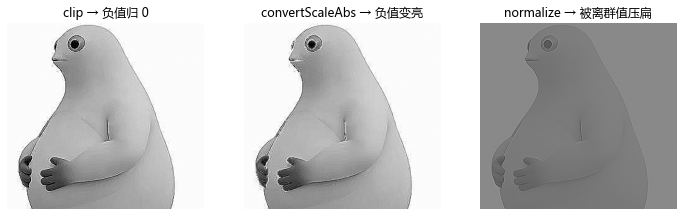


三帧都带小数（占比 61%）
   每帧先 astype(uint8) 再平均（错）-> 均值 204.6529
   全程 float32、最后再转（对）      -> 均值 204.9383
   差 0.2854 —— 截断每次都往下取整，误差一路累积


In [3]:
# 演示 2：带小数的像素值，到底怎么处理
img = cv2.imread('res/nl_side.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
g32 = gray.astype(np.float32)

# ① 小数从哪来：类型跟着输入走
blur32 = cv2.GaussianBlur(g32, (5, 5), 0)
frac = np.count_nonzero(blur32 != np.round(blur32))
print("float32 高斯滤波后 ->", blur32.dtype,
      "  带小数的像素占 %.0f%%" % (100 * frac / blur32.size))
print("随手取几个值:", np.round(blur32.ravel()[:6], 3))
print("→ 输入 float32，滤波结果还是 float32，小数会一路留着")

# ② 头号大坑：astype(np.uint8) 是截断，负数还会回绕
vals = np.array([0.6, 1.6, 127.5, 254.6, -0.5, -1.5, -2.7, 255.0, 300.6], np.float64)
print("\n直接 .astype(np.uint8)：")
for v, u in zip(vals, vals.astype(np.uint8)):
    flag = '   <-- 回绕！' if (v < 0 or v > 255) else ''
    print("   %8.2f -> %3d%s" % (v, u, flag))
print("→ 正数只是被截断（0.6 变 0），负数和越界值会回绕成大白点")

# ③ 正确姿势：clip -> round -> astype
print("\n正确写法 np.clip(vals, 0, 255).round().astype(np.uint8)：")
print("   输入:", vals)
print("   输出:", np.clip(vals, 0, 255).round().astype(np.uint8))

# ④ convertScaleAbs：取绝对值 + 四舍五入 + 饱和（专给负梯度用）
print("\ncv2.convertScaleAbs（注意是取绝对值，所以负数会变亮）：")
print("   输出:", cv2.convertScaleAbs(vals.astype(np.float32).reshape(1, -1)).ravel())

# ⑤ 浮点结果范围超出 0~255 时，三种"救回来"的方式对比
kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
sharp32 = cv2.filter2D(g32, cv2.CV_32F, kernel)
print("\n锐化结果数值范围: %.0f ~ %.0f（负值像素占 %.0f%%）"
      % (sharp32.min(), sharp32.max(), 100 * np.count_nonzero(sharp32 < 0) / sharp32.size))

show_img(np.clip(sharp32, 0, 255).round().astype(np.uint8),
         cv2.convertScaleAbs(sharp32),
         cv2.normalize(sharp32, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8),
         titles=['clip → 负值归 0', 'convertScaleAbs → 负值变亮',
                 'normalize → 被离群值压扁'])

# ⑥ 多帧平均降噪：全程 float32，最后才转
frames = [cv2.GaussianBlur(g32, (k, k), 0) for k in (3, 5, 7)]     # 三"帧"，都带小数
acc = sum(f / 3.0 for f in frames)                                 # 全程浮点
bad = sum(f.astype(np.uint8).astype(np.float32) / 3.0 for f in frames)   # 每帧先截断
print("\n三帧都带小数（占比 %.0f%%）"
      % (100 * np.count_nonzero(acc != np.round(acc)) / acc.size))
print("   每帧先 astype(uint8) 再平均（错）-> 均值 %.4f" % bad.mean())
print("   全程 float32、最后再转（对）      -> 均值 %.4f" % np.round(acc).astype(np.uint8).mean())
print("   差 %.4f —— 截断每次都往下取整，误差一路累积" % (np.round(acc).astype(np.uint8).mean() - bad.mean()))


### ✍️ 练习

1. 对 `res/nl_side.png` 做 `cv2.Sobel(gray, cv2.CV_32F, 1, 0)`，打印结果的 `min()` / `max()`；
   再换成 `ddepth=-1` 做一遍，解释两次结果为什么差这么多。
2. 把一张图转成 `np.float32` 后除以 255（值域变 0~1），分别用 `astype(np.uint8)` 和
   `np.clip(f, 0, 255).round().astype(np.uint8)` 转一次，各存一张 PNG，并排显示，指出差别在哪。
3. 用 `res/nl_video.mp4` 抽 30 帧，逐帧转 `float32` 累加求平均做降噪，最后再转回 `uint8`；
   再把"每帧先 `astype(np.uint8)` 再平均"的版本存一份，比较两者的均值差异。
4. **思考题**：`cv2.normalize(f, None, 0, 255, cv2.NORM_MINMAX)` 为什么有时候会让整张图
   变成一片均匀的灰？该怎么避免？



---

# 延伸阅读（本讲义不展开）

到这里 `cv2` 讲义的主要内容就讲完了。还有几块属于**其他主题**，简单介绍，感兴趣自己查：

## 其他形态学算子

| 操作 | 函数 | 作用 |
| --- | --- | --- |
| 形态学梯度 | `MORPH_GRADIENT` | 膨胀 − 腐蚀 = 粗轮廓 |
| 顶帽 | `MORPH_TOPHAT` | 原图 − 开运算 = 亮细节（**用在灰度图上**） |
| 黑帽 | `MORPH_BLACKHAT` | 闭运算 − 原图 = 暗细节（**用在灰度图上**） |

> 注意：顶帽 / 黑帽用在**已经是二值图**的图上，结果几乎全是黑的 ——
> 它们本来就是用来提取灰度图里的细节的。

## 其他几何变换

| 变换 | 函数 | 点对数量 |
| --- | --- | --- |
| 缩放 | `cv2.resize` | — |
| 平移 / 旋转 | `cv2.warpAffine` + `getRotationMatrix2D` | — |
| **仿射** | `cv2.getAffineTransform` | **3 组** |
| 透视 | `cv2.getPerspectiveTransform` + `cv2.warpPerspective` | **4 组** |

## 还没碰过的几个方向

| 方向 | 关键词 |
| --- | --- |
| 直方图 | `cv2.calcHist`、`cv2.equalizeHist`（直方图均衡化） |
| 模板匹配 | `cv2.matchTemplate`（找"图中图"） |
| 特征点 | SIFT / ORB / `cv2.BFMatcher`（图像拼接、SLAM 的基础） |
| 光流 | `cv2.calcOpticalFlowPyrLK`（跟踪运动） |
| 深度学习 | `cv2.dnn`（加载 ONNX / Caffe 模型做推理） |

> 这几块要么自成体系，要么需要额外的前置知识，建议**用到时再单独开一节学**。

---

# 附录 A · 速查表（选学部分）

## 卷积与滤波

| 函数 | 说明 |
| --- | --- |
| `cv2.filter2D(src, ddepth, kernel)` | 自定义卷积 |
| `cv2.convertScaleAbs(src)` | 取绝对值 + 转 uint8（**配合 CV_32F**） |
| `borderType` | `CONSTANT/REPLICATE/REFLECT/REFLECT_101/WRAP` |
| `cv2.getGaussianKernel(k, sigma)` | 一维高斯核 |
| `cv2.blur` / `cv2.GaussianBlur` / `cv2.medianBlur` / `cv2.bilateralFilter` | 均值 / 高斯 / 中值 / 双边滤波 |

## 边缘检测

| 函数 | 说明 |
| --- | --- |
| `cv2.Sobel(gray, ddepth, dx, dy, ksize)` | 一阶导，可分方向 |
| `cv2.Scharr(gray, ddepth, dx, dy)` | 一阶导，3×3 更准 |
| `cv2.Laplacian(gray, ddepth)` | 二阶导，怕噪声 |
| `cv2.Canny(gray, t1, t2, apertureSize, L2gradient)` | 综合最优 |

## 二值化与阈值

| 函数 | 说明 |
| --- | --- |
| `cv2.threshold(src, thresh, maxval, type)` | **返回 `(retval, dst)` 两个值** |
| `THRESH_BINARY` / `THRESH_BINARY_INV` | 亮的变白 / 暗的变白（最常用） |
| `THRESH_TRUNC` / `THRESH_TOZERO` / `THRESH_TOZERO_INV` | 截断 / 暗部压黑 / 亮部压黑 |
| `\| cv2.THRESH_OTSU` | **按位或**加到 `type` 上，自动求阈值（`thresh` 写 0） |
| `cv2.adaptiveThreshold(src, maxval, method, type, blockSize, C)` | 自适应阈值（光照不匀时用，`blockSize` 必须奇数） |

## 轮廓与形状

| 函数 | 说明 |
| --- | --- |
| `cv2.findContours(binary, mode, method)` | 需要单通道二值图 |
| `cv2.drawContours(img, cts, -1, color, thickness)` | 画轮廓 |
| `cv2.contourArea` / `cv2.arcLength` / `cv2.isContourConvex` | 面积 / 周长 / 凸性 |
| `cv2.approxPolyDP(c, eps, True)` | 多边形逼近（`eps` 单位是像素） |
| `cv2.moments(c)` | 求质心 |
| `cv2.boundingRect(c)` | 正外接矩形 |
| `cv2.minAreaRect(c)` / `cv2.boxPoints(r)` | 旋转外接矩形 / 取它的 4 个顶点 |
| `cv2.minEnclosingCircle(c)` | 最小外接圆 |
| `cv2.convexHull(c)` | 凸包 |

## 形态学

| 函数 | 说明 |
| --- | --- |
| `cv2.getStructuringElement(shape, ksize)` | 造结构元素，`ksize` 是 **`(宽, 高)`** |
| `cv2.erode` / `cv2.dilate` | 腐蚀（取最小）/ 膨胀（取最大），`iterations` 控制次数 |
| `cv2.morphologyEx(src, MORPH_OPEN, k)` | 开运算：先腐蚀再膨胀，**去小白点** |
| `cv2.morphologyEx(src, MORPH_CLOSE, k)` | 闭运算：先膨胀再腐蚀，**补小空洞** |
| `MORPH_GRADIENT` / `MORPH_TOPHAT` / `MORPH_BLACKHAT` | 粗轮廓 / 亮细节 / 暗细节 |

## 霍夫变换

| 函数 | 输入 | 返回 |
| --- | --- | --- |
| `cv2.HoughLines(edges, rho, theta, threshold)` | **Canny 边缘图** | `(N,1,2)` 的 `(rho, theta)` |
| `cv2.HoughLinesP(edges, rho, theta, threshold, minLineLength, maxLineGap)` | Canny 边缘图 | `(N,1,4)` 的 `(x1,y1,x2,y2)` |
| `cv2.HoughCircles(gray, HOUGH_GRADIENT, dp, minDist, param1, param2, minRadius, maxRadius)` | **灰度图**（别二值化） | `(1,N,3)` 的 `(x, y, r)` |

> **三个函数都可能在没检测到结果时返回 `None`** —— 用之前先判空。

## 几何变换

| 函数 | 说明 |
| --- | --- |
| `cv2.resize(img, (w, h), interpolation=...)` | 缩放 |
| `cv2.getRotationMatrix2D(center, angle, scale)` + `cv2.warpAffine` | 旋转 |
| `cv2.getAffineTransform(src3, dst3)` | 仿射，**3 组点** |
| `cv2.getPerspectiveTransform(src4, dst4)` + `cv2.warpPerspective(img, M, (w, h))` | 透视，**4 组点**，`src/dst` 必须是 `np.float32` |


# 附录 B · 学完之后

选学的内容在真实项目里用得非常多：

| 项目 | 用到本讲义哪部分 |
| --- | --- |
| 文档扫描矫正 | 选学第 2 章二值化 → 选学第 3 章轮廓 → 选学第 4 章 `approxPolyDP` → **必修第 9 章透视变换** |
| 车道线检测 | 第 1 章 Canny → ROI → 第 5 章 `HoughLinesP` |
| 硬币 / 零件计数 | **必修第 6 章形态学** → 选学第 3 章轮廓 → 选学第 5 章 `HoughCircles` |
| 零件尺寸测量 | 选学第 2 章阈值 → 选学第 3 章轮廓 → 选学第 4 章 `minAreaRect` → 像素/毫米标定 |
| 目标定位抓取 | **必修第 5 章颜色分割 → 必修第 6 章形态学清理** → 选学第 3 章轮廓 → 选学第 4 章 `boundingRect` |
| 机器人地面标定 | **必修第 9 章透视变换**（斜视 → 俯视） |

---

## 结语

送给你四句话：

1. **一切滤波都是卷积** —— 核设计好了，效果自然对
2. **边缘是"梯度大"的地方** —— 所以求导算子都能检测边缘
3. **二值图是后面所有操作的总闸门** —— 阈值调不好，后面全白搭
4. **轮廓把"边缘"变成"可以用数字描述的形状"** —— 面积、周长、外接框、角点，从此可以写判定逻辑

---

*本讲义依据 RobotIC 算法培训讲义 `cv2`（第二讲 · OpenCV 操作进阶）整理，
素材来自 `cv2` 讲义原始素材与 `wallpaper-main` 奶蛙图库。*

---

> 🙏 **致谢学长**
>
> 这份讲义是在学长们整理的《RobotIC 算法培训讲义》（`cv1` / `cv2`）的基础上重写的。
> 章节顺序怎么排、哪些坑必须提前提-—
> 这些判断都是学长们自己踩过一遍、又讲给一届届新人，才一点点沉淀下来的。
>
> **谢谢学长们把路铺好。我们接着往下传。**
